# 08 · 대표 6종 ETF 공동 SVR–GARCH–CUSUM 바텀업 통계 식별

**「여섯 ETF의 공동 SVR–GARCH–CUSUM 불안정성에 대한 단계적 통계적 식별: 기존 동적 시장 동조구조 대비 추가 공동 반응의 검정」**

- 연구 ID `R2H_W3_JOINT_CUSUM_08`, 프로토콜 `W3-lock-2`.
- 계약: `research/joint_cusum_w3/W3_연구계약.md` (lock-1 `9cdeccb`) 와 `W3_계약개정_lock2.md` (`955d126`).
- 설정: `configs/t15_joint_cusum_w3_v2.json`.
- 반복 수 동결 기록: `MC_REPS_FREEZE.md`.
- 모든 규칙은 실제 ETF 의 공동 통계량을 계산하기 **전에** 커밋했다.

이 노트북이 최대화하는 것은 유의한 구간의 **개수가 아니다**. 통계적 식별의 신뢰성, 검출력 평가의 정확성, 정보 가용성 준수, 재현성이다. 검정이 부정적이거나, 귀무모형이 부적합하거나, 계산이 부족하면 그것도 결과로 보고한다.

## 0. 실행 환경·동결 지문

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t15_joint_cusum_w3_v2.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import csv  # 보호 파일 SHA 목록
import gzip  # Git 제외 일별 표 압축
import hashlib  # 결과 해시
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import json  # 설정·메타
import platform  # Python 버전

import matplotlib.pyplot as plt  # 그림 기본 설정
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, display  # 표·그림 출력
from matplotlib import font_manager  # 한글 글꼴 등록

# T12·W1·W2 재현 환경과 같은 버전이어야 한다 (user-site 의 다른 numpy/pandas 를 잡으면 여기서 멈춘다).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scipy": "1.18.1", "matplotlib": "3.11.2"}  # 고정 환경
ACTUAL_ENV = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": metadata.version("scipy"), "matplotlib": metadata.version("matplotlib")}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패로 처리
assert "site-packages" in np.__file__ and ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = [font_manager.FontProperties(fname=str(FONT_FILE)).get_name(), "DejaVu Sans"]  # 한글 우선·기호 대체
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지
pd.set_option("display.width", 220)  # 표 줄바꿈 완화
pd.set_option("display.max_columns", 40)  # 열 생략 완화

from r2h.joint_cusum import analysis as A  # W3 관측 분석 (MC 와 같은 함수 경로)
from r2h.joint_cusum import figures as F  # W3 그림
from r2h.joint_cusum.pipeline import load_cfg  # W3 동결 설정 (lock-2)

assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
CFG = load_cfg()  # 동결 설정 configs/t15_joint_cusum_w3_v2.json
BASE = ROOT / "research/joint_cusum_w3"  # W3 산출물 폴더
RES = BASE / "results/08"  # 집계 결과 (Git 포함)
FIG = BASE / "figures"  # 그림 (PNG 320dpi + SVG)
WORK = ROOT / "outputs/t15/08"  # 일별 표 (Git 제외 — 가격 역산 가능)
for d in (RES, FIG, WORK):  # 폴더 준비
    d.mkdir(parents=True, exist_ok=True)  # 없으면 만든다


def sha(p):  # 파일 SHA256
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()  # 바이트 단위 지문


# 계약·설정 동결 지문 (lock-1 기록 + lock-2 개정) 과 보호 파일 252개를 대조한다.
for line in (BASE / "CONTRACT_FREEZE_SHA256.txt").read_text().splitlines():  # 동결 기록 4줄
    digest, name = line.split(maxsplit=1)  # 해시·경로
    assert sha(ROOT / name) == digest, f"동결 파일 변경: {name}"  # 결과를 본 뒤 규칙 변경 금지
PROTECTED = list(csv.DictReader(open(BASE / "W3_PROTECTED_SHA256.csv", encoding="utf-8")))  # W1·W2·T12·노트북 00–07
CHANGED = [r["path"] for r in PROTECTED if sha(ROOT / r["path"]) != r["sha256"]]  # 바뀐 보호 파일
assert not CHANGED, f"보호 파일 변경: {CHANGED}"  # 기존 연구는 읽기만
META = json.loads((ROOT / "outputs/t15/mc/inference_meta.json").read_text())  # MC 완료 시점·산출 해시
BAD_MC = [n for n, h in META["files"].items() if sha(ROOT / "outputs/t15/mc" / n) != h]  # MC 산출물 변조 검사
assert not BAD_MC, f"MC 산출물이 기록과 다름: {BAD_MC}"  # 기록된 MC 결과만 쓴다


def save_csv(df, name):  # 결과표 저장 (결정적 형식)
    df.to_csv(RES / name, index=False, float_format="%.10g")  # 반올림 형식 고정
    return RES / name  # 경로 반환


print("작업트리:", ROOT)  # 실행 위치
print("프로토콜:", CFG["protocol_version"], "| 보호 파일", len(PROTECTED), "개 불변 | MC 완료:", META["completed_at"])  # 동결 지문
print("실행 환경:", ACTUAL_ENV)  # 환경 기록

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1017_2/R2H_W3_Joint_CUSUM
프로토콜: W3-lock-2 | 보호 파일 252 개 불변 | MC 완료: 2026-10-18
실행 환경: {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


## 01. W1/W2 연구 승계와 W3 문제 정의

**무엇을 승계하는가.**

| 단계 | 결론 | W3 에서의 쓰임 |
|---|---|---|
| T12 | 연간 expanding SVR–GARCH 잔차, 정책 A·B·base | 같은 함수로 관측·모의 잔차를 만든다 (`fit_annual`·`forecast_year`) |
| W1 (03·04) | 이동 CUSUM 적격 창 **0/4** (최적창 없음) | 판정을 바꾸지 않는다. CUSUM 통계량 T_w 는 공동 검정의 재료로만 쓴다 |
| W2 (05–07) | 다중 기간 변동성 상태, 공통 구간 (탐색적, 귀무 보정 없음) | 구조변화 정답이 아니다. q 특징 규칙만 승계해 순차 탐지에 쓴다 |

**W3 의 문제.** W2 의 공통성은 "같은 날 여러 ETF 가 반응했다" 는 **관찰**이었다. W3 는 두 가지를 묻는다.
1. 그 공동 반응이 **기존 시장 동조성**으로 설명되는가? 이를 위해 동조성을 보존한 귀무모형(H0-B: DCC-t)을 모든 반복에서 연간 SVR 재적합까지 포함해 모의한다.
2. 바텀업으로 자산을 하나씩 더할 때 새 자산이 **추가 정보**를 주는가?

**한계.**
- 2021–2025 는 이미 W1·W2 에서 본 자료다. 이 노트북의 결과는 독립 외부 검증이 아니다.
- 모든 p 값은 지정한 귀무모형에 조건부다.

## 02. 여섯 ETF·세 정책·바텀업 가설

| 코드 | 종목 | 단계 |
|---|---|---|
| 069500 | KODEX 200 | S1 (기준 ETF) |
| 229200 | KODEX 코스닥150 | S1 |
| 148070 | KIWOOM 국고채10년 | S2 신규 |
| 153130 | KODEX 단기채권 | S3 신규 |
| 133690 | TIGER 미국나스닥100 | S4 신규 |
| 261220 | KODEX WTI원유선물(H) | S5 신규 |

- S1 ⊂ S2 ⊂ … ⊂ S5 의 순서는 결과와 무관하게 고정했다.
- 부분 분석은 크기 2 이상 **57개 부분집합 전부**다 (15·20·15·6·1).

| 가설 | 검정 | α |
|---|---|---|
| H1 개별 잔차 분산 불안정성 | 기술 (W1 0/4 유지) | — |
| H2 (H0-A) 시간 정렬 이상의 공동 반응 | 보조. 원형 이동·블록 재표집 | 보조 |
| **H3 (H0-B) 동적 시장 동조 이상의 공동 불안정성** | **주 검정** (DCC-t, 전체 재적합 MC) | 주 경로 0.02 · 부분집합 0.02 |
| H4 신규 ETF 조건부 참여 | S2–S5 고정 순서 | 각 0.02 (사슬) |
| H5 의존구조 자체의 변화 | 보조 진단 (V6 합성 + 구간 전후 상관) | — |
| H6 사후 가격 반응 | `EXPLORATORY_REUSED_DATA` | 0.01 예약 (미사용) |

**정책.** A 는 관측 proxy, B 는 재귀 예측, base 는 직전 60일 표본분산이다. 세 정책을 동등하게 다룬다. 결과를 본 뒤 주 정책을 고르지 않는다.

## 03. 원자료·모형·워크포워드 시간 계약

**두 시간 기준.**
- **A. 워크포워드 관측.**
  - 연간 SVR 은 그해 이전 자료로 적합하고 파라미터를 고정한다. 예측분산과 잔차는 날마다 순차로 계산한다.
  - 날짜 t 의 신호는 t 종가 뒤에 확정된다.
  - 시차 탐색이 미래 날짜의 신호를 썼다면, 그 공동 신호는 가장 늦은 참여 신호의 날에야 알 수 있다 (`joint_confirmed_at`).
- **B. 사후 통계 식별.** 2021–2025 전체의 최대통계량 p 값과 구간 순위는 당시 쓸 수 있던 정보가 아니다 (`retrospective_p_value`, `inference_completed_at`).

**첫 검증.**
- 이 노트북은 관측 6종을 MC 반복과 **같은 함수**(`run_pipeline`) 로 처리한다.
- 그 결과는 T12 cache 의 e·vhat 과 같아야 한다. 같아야 관측 통계량과 귀무 통계량이 같은 구성이 된다.

In [2]:
# 관측 6종: 원자료 → 연간 SVR 재적합 → 정책별 잔차 → 연도 안 이동창 CUSUM → 위치 구간별 꼬리점수 Q
OBS = A.load_obs(CFG, ROOT)  # MC 반복과 같은 run_pipeline·q_score
print("평가일:", OBS.dates[0].date(), "~", OBS.dates[-1].date(), len(OBS.dates), "일 | 배열 T:", OBS.out.T.shape, "| Q:", OBS.Q.shape)  # 범위 확인
# T12 cache 의 e·vhat 과 대조 (CSV 반올림 이내여야 같은 함수 경로)
T12 = ROOT.parents[1] / "1016/R2H_T12_Final/outputs/t12/work/b_nb_20261016T181251"  # T12 동결 cache
rec = []  # ETF·정책별 최대 차
for i, tk in enumerate(OBS.tickers):  # 6종
    d = pd.read_csv(T12 / tk / "daily.csv.gz", dtype={"ticker": str, "policy": str}, parse_dates=["date"])  # cache 일별
    for p_i, p in enumerate(("A", "B", "base")):  # 세 정책
        b = d[(d.window == 0) & (d.policy == p)].set_index("date").reindex(OBS.dates)  # 같은 날짜로 정렬
        rec.append({"ticker": tk, "policy": p, "max_abs_de": float(np.nanmax(np.abs(b.e.to_numpy() - OBS.out.e[i, p_i]))), "max_abs_dvhat": float(np.nanmax(np.abs(b.vhat.to_numpy() - OBS.out.vhat[i, p_i]))), "nan_mismatch": int((np.isnan(b.e.to_numpy()) != np.isnan(OBS.out.e[i, p_i])).sum())})  # 차이
REPRO = pd.DataFrame(rec)  # 재현 대조표
save_csv(REPRO, "t12_reproduction_check.csv")  # 근거 저장
assert REPRO.max_abs_de.max() < 1e-8 and REPRO.nan_mismatch.sum() == 0, REPRO  # 같은 함수 경로 확인
display(REPRO.describe().loc[["max"]])  # 최대 차만 표시

평가일: 2021-01-04 ~ 2025-12-30 1225 일 | 배열 T: (6, 3, 7, 1225) | Q: (6, 3, 4, 1225)


,max_abs_de,max_abs_dvhat,nan_mismatch
max,3.936288e-09,4.204369e-08,0.0


In [3]:
# W1 common 표본 무결성 대조: W1 동결 임계값으로 6종 일별 경보를 다시 세어 W1 집계와 맞춘다 (lock-2 §6)
from r2h.multihorizon.cusum import (  # W2 가 쓴 대조 함수
    critical_tables,  # W1·T12 임계값 표
    daily_cusum,  # 일별 경보 재계산
    load_daily_cache,  # T12 일별 cache 읽기
    verify_against_w1,  # W1 집계와 행 단위 대조
)
from r2h.window_study.simulation import load_cfg as load_w1_cfg  # W1 동결 설정

W1CFG = load_w1_cfg(ROOT)  # W1 동결 설정 configs/t13_window_study_v1.json
SRC = ROOT.parents[1] / "1016/R2H_T12_Final"  # T12 종결 작업트리
pipe_c, point_c = critical_tables(SRC, W1CFG["base_t12_run_id"], ROOT)  # W1·T12 임계값
cus = pd.concat([daily_cusum(t, load_daily_cache(SRC, W1CFG["base_t12_run_id"], t), W1CFG, pipe_c, point_c, [20, 30, 60, 120]) for t in OBS.tickers])  # 6종 일별 경보
w1m = pd.read_csv(ROOT / "research/window_study_w1/results/04_real/alarm_metrics.csv", dtype={"ticker": str})  # W1 집계
w1m = w1m[w1m.ticker.str.zfill(6).isin(OBS.tickers)]  # 6종만
W1CHK = verify_against_w1(cus, w1m, [20, 30, 60, 120], W1CFG["episode_gap_non_alarm_days"])  # 행 단위 대조
save_csv(W1CHK[["ticker", "year", "policy", "w", "threshold_type", "sample_type", "match"]], "w1_common_integrity_check.csv")  # 근거
print("W1 집계 대조:", int(W1CHK.match.sum()), "/", len(W1CHK), "행 일치")  # 결과
assert W1CHK.match.all(), W1CHK[~W1CHK.match].head()  # 전부 일치해야 한다

W1 집계 대조: 2016 / 2016 행 일치


## 04. ETF별 개별 CUSUM 경로 및 적격성

**문제.** 여섯 ETF 의 개별 CUSUM 은 언제, 얼마나 크게 반응했는가?

**산식.**
- T_{i,p,w,t} 는 W1 원 함수 `rolling_cusum` 으로 계산한다. 그해 잔차 안에서만 계산하며, 첫 유효 위치는 w−1 이다.
- 그 이전 날짜는 `NOT_AVAILABLE` 이고, 무경보로 바꾸지 않는다.
- 개별 경보 기준은 **W3 own-valid 보정 임계값**이다 (lock-2 §6). H0_CALIBRATION 반복에서 그해 own-valid 일의 최대 T 를 모으고, 그 95% 분위를 ETF·정책·창마다 따로 쓴다.
- W1 동결 임계값은 무결성 대조용으로만 쓴다.

In [4]:
# ETF·정책·창별 개별 CUSUM 요약: 유효일·W3 경보일·W1 기준 경보일(참고)·최대 T
FLAGS3 = A.cusum_alarm_flags(OBS, "w3")  # 주: W3 own-valid 보정 임계값
FLAGS1 = A.cusum_alarm_flags(OBS, "w1")  # 참고: W1 동결 임계값
CRIT3 = json.loads((ROOT / "outputs/t15/mc/w3_individual_criticals.json").read_text())  # W3 임계값
rows = []  # 요약 행
for i, tk in enumerate(OBS.tickers):  # 6종
    for p_i, p in enumerate(("A", "B", "base")):  # 세 정책
        for w_i, w in enumerate((20, 30, 60, 120)):  # 네 창
            T = OBS.out.T[i, p_i, w_i]  # 일별 통계량
            rows.append({"ticker": tk, "policy": p, "w": w, "valid_days": int(np.isfinite(T).sum()), "not_available_days": int((~np.isfinite(T)).sum()), "crit_w3": CRIT3[f"w3:{tk}:{p}:{w}"], "alarm_days_w3": int(FLAGS3[tk, p, w].sum()), "alarm_days_w1_ref": int(FLAGS1[tk, p, w].sum()), "max_T": float(np.nanmax(T)), "max_Q": float(np.nanmax(OBS.Q[i, p_i, w_i]))})  # 한 칸
INDIV = pd.DataFrame(rows)  # 개별 CUSUM 요약
save_csv(INDIV, "individual_cusum_summary.csv")  # 근거 저장
display(INDIV.pivot_table(index="ticker", columns=["policy"], values="alarm_days_w3", aggfunc="sum"))  # ETF×정책 경보일 합
display(INDIV.groupby("w")[["valid_days", "not_available_days"]].first())  # 창별 계산 가능일 (연초 불능)

policy,A,B,base
ticker,,,
069500,0,0,0
133690,0,3,1
148070,0,0,0
153130,17,0,15
229200,0,0,0
261220,9,0,0


,valid_days,not_available_days
w,,
20,1130,95
30,1080,145
60,930,295
120,630,595


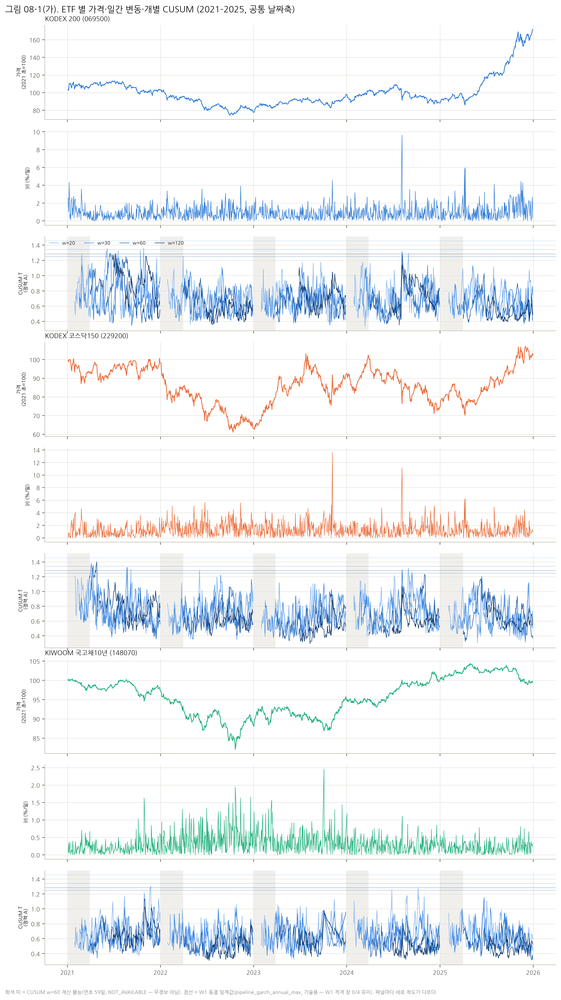

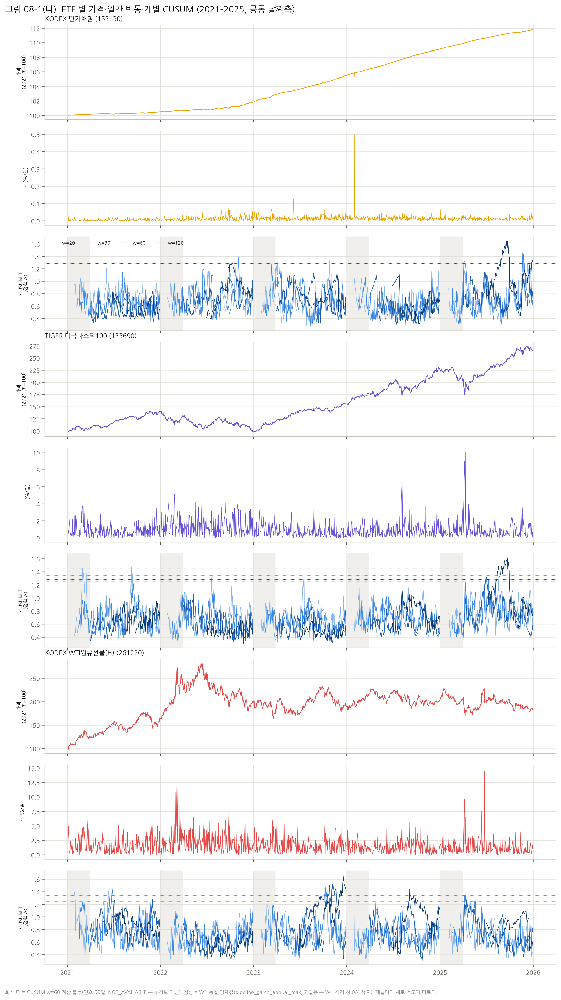

In [5]:
# 그림 08-1 (가·나): 공통 날짜축의 가격·|r|·정책 A CUSUM (패널별 척도)
NAMES = CFG["universe"]["names"]  # 종목명
PIPE = {(p, w): pipe_c[p, w] for p in ("A", "B", "base") for w in (20, 30, 60, 120)}  # W1 임계값 (점선 참고)
P1a = F.fig_individual(OBS, NAMES, PIPE, ["069500", "229200", "148070"], FIG, "08-1(가)")  # 국내 주식·국채
P1b = F.fig_individual(OBS, NAMES, PIPE, ["153130", "133690", "261220"], FIG, "08-1(나)")  # 단기채·나스닥·원유
display(Image(filename=str(P1a[0]), width=900))  # 렌더 확인
display(Image(filename=str(P1b[0]), width=900))  # 렌더 확인

**해석 (04).**
- **개별 경보.** W3 own-valid 보정 임계값 기준으로 5년 동안 개별 경보일을 셌다 (6종 × 3정책 × 4창 합산).
  - 153130 32일, 261220 9일, 133690 4일이다. **069500·229200·148070 은 0일**이다.
  - W1 동결 임계값으로 세면 186일이다. 이 값은 참고용이다.
- **임계값이 높아진 이유.** 평가연도별 DCC-t 귀무에서 연간 SVR 재적합까지 포함해 모의하면, 정상 시장에서도 CUSUM 연간 최대가 크게 나온다. 그래서 W3 임계값은 W1 값보다 높다.
- **경보 정의.** "경보" 는 ETF-연도마다 귀무 5% 가 넘는 일이 생기도록 정의했다. 경보가 0이라는 사실은 관측 CUSUM 이 그해 귀무 연간 최대의 95% 분위를 넘지 않았다는 뜻일 뿐이다.
- **계산 가능일.** 창이 길수록 연초 계산 불능이 커진다. w=20 은 1,130일 중 95일이 불능이고, w=120 은 630일만 계산되고 595일이 불능이다. 이 불능일은 무경보로 세지 않았다.
- **한계.** CUSUM 은 SVR 예측분산으로 표준화한 잔차의 통계량이다. 그래서 예측분산이 변동성 상승을 빠르게 흡수하면 반응이 작아진다 (T12·W1 과 같은 구조).

## 05. 1·3·7·14일 단기 변동성 순차 탐지

**문제.** 어떤 ETF 가 3일 신호에 먼저 반응하고, 어떤 ETF 가 20·60·120일 CUSUM 에서 늦게 반응하는가? 실제 일별 정보만 써서 답한다.

**산식.**
- **W2 q 특징.**
  - V⁽q⁾ = mean r² 이고, D⁽q⁾ = log(V_t/V_{t−q}) (q≥3) 다.
  - U 는 엄밀한 과거 확장형 mid-rank 분위이고, 최소 252개 값이 필요하다.
  - 확대 후보는 U_D ≥ 0.90, 고변동성 후보는 U_V ≥ 0.90 이다.
  - q=1 은 일간 충격이다.
- **잔차 에너지 (승인서 §5.3).**
  - E⁽ʰ⁾_t = log(mean e²[t−h+1..t] / mean e²[t−h−59..t−h]) 이고, h ∈ {1,3,7,14} 다.
  - 그해 잔차 안에서만 계산하고, 분모가 0이면 NaN 이다.
  - H0_CALIBRATION 꼬리 1% 를 탐색 후보로 쓴다.
- **지위.** 이 단기 신호들은 **분위 기반 탐색 후보**이며 가족 보정 경보가 아니다. 귀무에서의 후보일 비율은 holdout 반복으로 따로 보인다.

In [6]:
# ETF 별 일별 q 신호 · E(h) 후보 · CUSUM 경보 에피소드별 '단기 후보 → 경보' 지연
QS = A.q_signals(OBS)  # W2 규칙 (q=1·3·7·14·20·30·60·120)
ECAND = A.energy_candidates(OBS)  # E(h) 보정 꼬리 1% 후보
SEQ = A.sequential_alarm_episodes(OBS, QS, FLAGS3, ECAND)  # W3 경보 에피소드별 지연
save_csv(SEQ, "sequential_alarm_episodes.csv")  # 근거
LAGSUM = SEQ.groupby(["ticker", "w"]).agg(alarm_episodes=("alarm_days", "size"), share_preceded_q3=("lag_from_q3_EXP", lambda s: float(s.notna().mean())), median_lag_q3=("lag_from_q3_EXP", "median"), median_lag_q7=("lag_from_q7_EXP", "median"), median_lag_E3=("lag_from_E3", "median")).reset_index()  # ETF×창 요약
save_csv(LAGSUM, "sequential_lag_summary.csv")  # 근거
display(LAGSUM)  # 표
HOLD_Q = np.load(ROOT / "outputs/t15/mc/null_eval_holdout.npz")["q_signal_rate"].mean(axis=0)  # 귀무 후보일 비율 (ETF, q, 채널)
QNULL = pd.DataFrame([{"ticker": tk, "q": q, "null_EXP_rate": HOLD_Q[i, k, 0], "null_HIGH_rate": HOLD_Q[i, k, 1]} for i, tk in enumerate(OBS.tickers) for k, q in enumerate((3, 7, 14))])  # 표
save_csv(QNULL, "q_candidate_rate_under_null.csv")  # 근거
display(QNULL.pivot(index="ticker", columns="q", values="null_EXP_rate").round(3))  # 귀무에서도 약 10% 가 후보

,ticker,w,alarm_episodes,share_preceded_q3,median_lag_q3,median_lag_q7,median_lag_E3
0,133690,20,3,1.0,7.0,14.0,50.0
1,153130,120,3,1.0,26.0,NaN,51.0
2,261220,60,3,1.0,22.0,22.0,21.0
3,261220,120,1,1.0,1.0,6.0,51.0


q,3,7,14
ticker,,,
069500,0.101,0.101,0.102
133690,0.101,0.101,0.100
148070,0.101,0.101,0.102
153130,0.101,0.101,0.102
229200,0.100,0.101,0.102
261220,0.100,0.101,0.102


,ticker,first_daily_shock_q1,first_EXP_q3,first_EXP_q7,first_EXP_q14,first_CUSUM_w20,first_CUSUM_w60,first_CUSUM_w120,last_CUSUM_w60
0,069500,2024-07-25,2024-08-02,2024-08-02,2024-08-02,NONE,NONE,NONE,NONE
1,229200,2024-08-02,2024-08-02,2024-08-05,2024-08-05,NONE,NONE,NONE,NONE
2,148070,2024-08-05,2024-07-25,2024-08-05,2024-08-07,NONE,NONE,NONE,NONE
3,153130,2024-07-25,2024-07-26,2024-09-13,NONE,NONE,NONE,2024-07-29,NONE
4,133690,2024-07-25,2024-07-26,2024-08-02,2024-07-30,NONE,NONE,NONE,NONE
5,261220,2024-08-05,2024-09-13,2024-08-07,2024-07-29,NONE,NONE,NONE,NONE


,ticker,first_daily_shock_q1,first_EXP_q3,first_EXP_q7,first_EXP_q14,first_CUSUM_w20,first_CUSUM_w60,first_CUSUM_w120,last_CUSUM_w60
0,069500,2025-03-31,2025-03-28,2025-04-04,2025-04-07,NONE,NONE,NONE,NONE
1,229200,2025-03-31,2025-04-09,2025-04-14,2025-04-10,NONE,NONE,NONE,NONE
2,148070,2025-05-19,2025-03-31,2025-04-07,2025-04-14,NONE,NONE,NONE,NONE
3,153130,2025-03-27,2025-03-28,2025-04-03,NONE,NONE,NONE,NONE,NONE
4,133690,2025-03-31,2025-04-07,2025-04-04,2025-04-04,NONE,NONE,NONE,NONE
5,261220,2025-04-04,2025-04-01,2025-04-04,2025-04-07,NONE,NONE,NONE,NONE


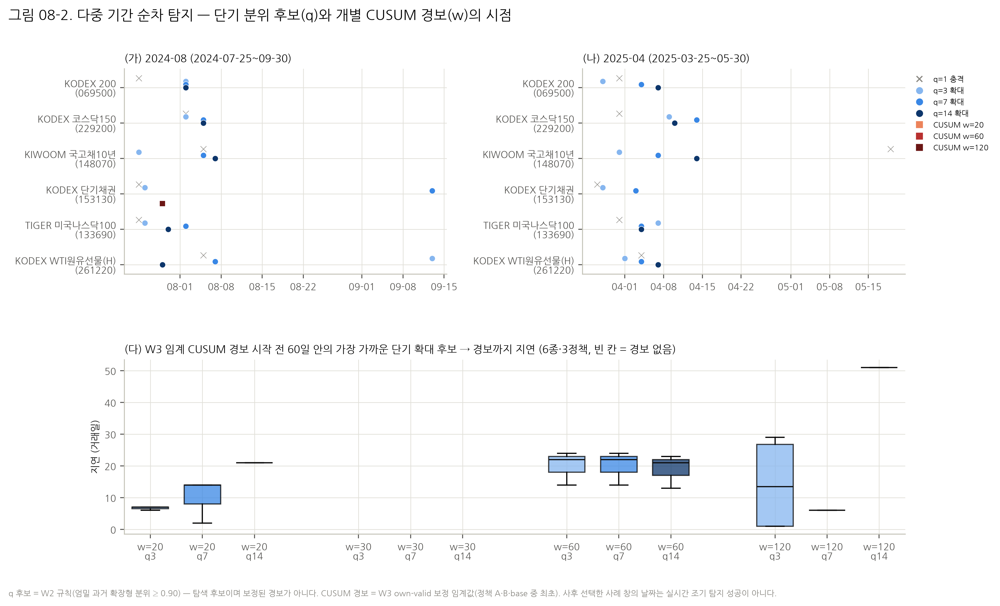

In [7]:
# 사례 창 순차 반응표 (2024-08 · 2025-04) 와 그림 08-2
CASES = {"2024-08 (2024-07-25~09-30)": ("2024-07-25", "2024-09-30"), "2025-04 (2025-03-25~05-30)": ("2025-03-25", "2025-05-30")}  # 승인서 §18 G6 사례
CASE_T = {k: A.case_sequence(OBS, QS, FLAGS3, a, b) for k, (a, b) in CASES.items()}  # ETF 별 첫 신호 날짜
for k, df in CASE_T.items():  # 두 사례
    save_csv(df, f"case_sequence_{k[:7]}.csv")  # 근거
    display(df[["ticker", "first_daily_shock_q1", "first_EXP_q3", "first_EXP_q7", "first_EXP_q14", "first_CUSUM_w20", "first_CUSUM_w60", "first_CUSUM_w120", "last_CUSUM_w60"]])  # 표
P2 = F.fig_sequence(CASE_T, SEQ, NAMES, FIG, "08-2")  # 순차 탐지 그림
display(Image(filename=str(P2[0]), width=950))  # 렌더 확인

In [8]:
# 단기 창 w=3·7·14 CUSUM 적격성 (W1 규칙을 W3 own-valid 표본에 적용) — 주 검정 가족에는 넣지 않는다
POWER = A.power_tables(OBS)  # 합성 검정력 (13장에서 자세히)
ELIG = A.short_window_eligibility(OBS, POWER["delays"])  # 크기·검출·지연·퇴화
save_csv(ELIG, "short_window_eligibility.csv")  # 근거
display(ELIG.groupby(["w", "role"]).agg(size_ok=("size_ok", "mean"), power_ok=("power_ok", "mean"), eligible=("verdict", lambda s: int((s == "ELIGIBLE").sum())), cells=("verdict", "size"), nan_share=("nan_share_own_valid", "max"), distinct_min=("distinct_values_200reps", "min")))  # 창별 요약

,,size_ok,power_ok,eligible,cells,nan_share,distinct_min
w,role,,,,,,
3,단기 적격성 연구,1.0,0.0,0,18,0.000819,205257
7,단기 적격성 연구,1.0,0.0,0,18,0.001598,236074
14,단기 적격성 연구,1.0,0.0,0,18,0.000625,229465
20,"주 창 (참고, W1 판정 불변)",1.0,0.0,0,18,0.000500,223633
30,"주 창 (참고, W1 판정 불변)",1.0,0.0,0,18,0.000505,213630
60,"주 창 (참고, W1 판정 불변)",1.0,0.0,0,18,0.000634,184252
120,"주 창 (참고, W1 판정 불변)",1.0,0.0,0,18,0.000627,125275


**해석 (05).**
- **단기 분위 후보는 귀무에서도 하루 약 10% 켜진다.** holdout 귀무에서 q=3·7·14 확대 후보일 비율은 0.100–0.102 였다. 정의상 분위 상위 10% 이기 때문이다.
  - 따라서 "단기 신호가 먼저 반응했다" 는 사실만으로는 변화를 탐지했다고 할 수 없다. 13장에서 귀무 기준선과 비교한다.
- **W3 임계 개별 CUSUM 경보.** 5년 동안 10개 에피소드뿐이다 (w=20 3, w=60 3, w=120 4).
  - 모든 에피소드 직전 60일 안에 q=3 확대 후보가 있었고, 경보까지의 지연 중앙값은 10.5 거래일이다.
  - 다만 후보가 하루 10% 확률로 켜지므로, 이 선행성은 귀무에서도 거의 늘 성립한다.
- **2024-08 사례.**
  - q=3 확대 후보가 069500·229200 은 08-02, 133690 은 07-26, 148070 은 07-25 에 처음 켜졌다.
  - W3 임계 CUSUM 경보는 153130 의 w=120 (07-29) 하나뿐이다.
- **2025-04 사례.**
  - q=3 후보는 069500 03-28, 261220 04-01, 133690 04-07, 229200 04-09 다.
  - 여섯 ETF 모두 W3 임계 CUSUM 경보가 **없었다**.
- **단기 창 적격성.** w=3·7·14 CUSUM 은 귀무 크기(ETF-연도당 0.050–0.051, Wilson 상한 ≤ 0.064)는 통과했다.
  - 그러나 V1 검출률이 0.009·0.011·0.016 에 그쳐 **18칸 모두 NOT_ELIGIBLE** 이다.
  - 참고 창 20·30·60·120 도 검출률 0.016–0.046 으로 모두 NOT_ELIGIBLE 이다. W1 의 0/4 와 같은 방향이지만, 다른 귀무에서 얻은 결과이므로 W1 판정을 다시 내린 것이 아니다.
- **G7 Q12 (단기 신호 대 중장기 CUSUM 의 검출 지연).**
  - 단기 분위 후보는 자주, 빨리 켜지지만 변화에 특이적이지 않다.
  - 중장기 CUSUM 은 거의 켜지지 않는다.
  - 둘 사이의 "지연" 은 어느 한쪽의 탐지 성능이 아니다.

## 06. 귀무 꼬리위치 및 공동 통계량

**산식 (lock-2 §7.1).**
- 개별 꼬리위치는 u = (1 + #{T* ≥ T}) / (N+1), Q = −log u 다.
  - T* 는 H0_CALIBRATION 2,000 반복의 같은 (ETF, 정책, 창, **연중 위치 구간**) 값이다.
  - 위치 구간은 [0,60)·[60,110)·[110,160)·[160,210)·[210,끝) 이다.
  - 풀 최대값을 넘으면 1/(N+1) 로 두고, 외삽하지 않는다.
- 공동 점수:
  - J_all(S) = min_{i∈S} Q̃_i, J_2(S) = 두 번째로 큰 Q̃_i 다.
  - Q̃ 는 기준 ETF 에서는 Q, 나머지에서는 max_{l∈{−2..2}} Q(t+l) 다.
- 비기준 ETF 의 반응 하나는 시차를 통해 최대 5개 기준일에 대응할 수 있다. 귀무 반복도 같은 규칙으로 계산하므로 보정된다.
- 133690 의 KRX 날짜 시차는 미국 기초시장 반영일 차이일 수 있다. 경제적 선후관계로 읽지 않는다.
- Q 는 개별 이례성 점수이며, 공동성의 보정 p 값이 아니다.

In [9]:
# 꼬리표 풀 크기와 관측 Q 분포, 57개 부분집합의 일별 공동 점수 (Git 제외 저장)
TT = OBS.tt  # 위치 구간별 꼬리표
POOL = pd.DataFrame([{"ticker": tk, "policy": p, "w": w, "bin": k, "n_pool": int(TT.n_pool[i, p_i, w_i, k])} for i, tk in enumerate(OBS.tickers) for p_i, p in enumerate(("A", "B", "base")) for w_i, w in enumerate((20, 30, 60, 120)) for k in range(len(TT.edges))])  # 칸별 풀 크기
save_csv(POOL, "tail_table_pool_sizes.csv")  # 근거
display(POOL.pivot_table(index="w", columns="bin", values="n_pool", aggfunc="min"))  # 창×위치 구간 최소 풀 (0 = 계산 불능 위치)
DAILY = pd.concat([A.joint_daily(OBS, s) for s in OBS.subsets], ignore_index=True)  # 집합×일 공동 점수
with gzip.GzipFile(WORK / "joint_daily.csv.gz", "wb", mtime=0) as fh:  # 결정적 gzip (Git 제외)
    fh.write(DAILY.to_csv(index=False, float_format="%.10g").encode())  # 일별 표
print("일별 공동 점수:", DAILY.shape, "| SHA256", sha(WORK / "joint_daily.csv.gz")[:16])  # 지문만 기록

bin,0,1,2,3,4
w,,,,,
20,409570,499506,499512,499442,349612
30,309679,499512,499522,499442,349591
60,9989,499526,499520,499479,349581
120,0,0,409594,499467,349564


일별 공동 점수: (69825, 13) | SHA256 00c7822d18aaddfc


## 07–09. S1 → S5 바텀업: 국내 주식 공동성과 신규 ETF 조건부 참여

**검정 통계량.**
- S1: M_S1 = max_{p,w,t} J_all(S1) 이다.
- S2–S5: C_Sk = max_{(p,w): |E|≥5} mean_{t∈E} Q̃_new 이고, E_{k−1} = {t : J_2(S_{k−1}) ≥ −log 0.01} 이다.
- **모든 귀무 반복에서 E 를 다시 만든다.** 무조건부 파이프라인 검정이며, 조건부 귀무와 섞지 않는다.

**판정.**
- 고정 순서 S1→S5, 각 단계 α=0.02 로 판정한다.
- 기각되지 않았거나 판정이 불가능한 단계에서 확증 사슬이 멈춘다. 멈춤은 후속 단계에 공동성이 없다는 뜻이 아니다.
- 다음 경우 그 단계는 `NULL_MODEL_INVALID` 다.
  - H0-B 유효성(N1·N3·N4) 이 실패한 경우
  - 조건부 귀무 유효성 검사(13장, V1·V2) 가 실패한 경우
- 단계별 J_all·J_2 는 α 밖의 기술 통계로 함께 낸다.

In [10]:
# 귀무 적합도 (N1·N3·N4·LB) → 통계량별 H0-B 유효성, 조건부 귀무 유효성 (V1·V2), 단계 판정
VAL = A.null_validity(OBS)  # 연도 모형별 envelope · 2/5 규칙
COND, COND_OK = A.conditional_null_check(OBS)  # 앞 단계만 변할 때 신규 ETF 검정의 기각률
TESTS = A.test_tables(OBS, VAL, COND_OK)  # 주 경로·부분집합 판정
STAGE = TESTS["stage"]  # S1–S5 표
save_csv(STAGE, "stage_tests.csv")  # 근거
save_csv(COND, "conditional_null_validity.csv")  # 근거
display(STAGE[["stage", "members", "obs", "p_dcc_label", "p_dcc_ci99_low", "p_dcc_ci99_high", "h0b_valid", "conditional_null_valid", "p_ccc", "p_h0a_circular_shift_within_year", "p_h0a_circular_block_bootstrap_within_year", "status", "confirmatory_status"]])  # 판정표
display(STAGE[["stage", "jall_obs", "jall_p_dcc_descriptive", "j2_obs", "j2_p_dcc_descriptive"]])  # 기술 통계 (α 밖)
display(COND)  # 조건부 귀무 유효성

,stage,members,obs,p_dcc_label,p_dcc_ci99_low,p_dcc_ci99_high,h0b_valid,conditional_null_valid,p_ccc,p_h0a_circular_shift_within_year,p_h0a_circular_block_bootstrap_within_year,status,confirmatory_status
0,S1,069500+229200,4.471162,0.8531,0.848999,0.857174,False,True,0.845231,0.626737,0.601740,NULL_MODEL_INVALID,NULL_MODEL_INVALID
1,S2,069500+229200+148070,NaN,,NaN,NaN,False,True,NaN,NaN,NaN,NOT_ESTIMABLE,CHAIN_STOPPED:NOT_ESTIMABLE
2,S3,069500+229200+148070+153130,NaN,,NaN,NaN,False,True,NaN,NaN,NaN,NOT_ESTIMABLE,CHAIN_STOPPED:NOT_ESTIMABLE
3,S4,069500+229200+148070+153130+133690,0.668924,0.8545,0.850394,0.858538,False,True,0.854829,0.261574,0.290671,NULL_MODEL_INVALID,CHAIN_STOPPED:NULL_MODEL_INVALID
4,S5,069500+229200+148070+153130+133690+261220,0.893038,0.9535,0.950980,0.955853,False,True,0.948010,0.760124,0.764124,NULL_MODEL_INVALID,CHAIN_STOPPED:NULL_MODEL_INVALID


,stage,jall_obs,jall_p_dcc_descriptive,j2_obs,j2_p_dcc_descriptive
0,S1,4.471162,0.853123,4.471162,0.853123
1,S2,4.182862,0.209996,4.689116,0.928321
2,S3,2.979389,0.449291,5.346670,0.801384
3,S4,2.233487,0.836743,5.346670,0.915302
4,S5,1.899369,0.921302,5.688659,0.873323


,scenario,stage,new_etf_unchanged,R,rejections,rate,wilson_low,wilson_high,alpha,conditional_null_valid
0,V1,S2,148070,300,2,0.006667,0.001830,0.023978,0.02,True
1,V1,S3,153130,300,8,0.026667,0.013573,0.051729,0.02,True
2,V1,S4,133690,300,7,0.023333,0.011348,0.047372,0.02,True
3,V1,S5,261220,300,7,0.023333,0.011348,0.047372,0.02,True
4,V2,S3,153130,300,5,0.016667,0.007139,0.038415,0.02,True
5,V2,S4,133690,300,7,0.023333,0.011348,0.047372,0.02,True
6,V2,S5,261220,300,6,0.020000,0.009198,0.042940,0.02,True


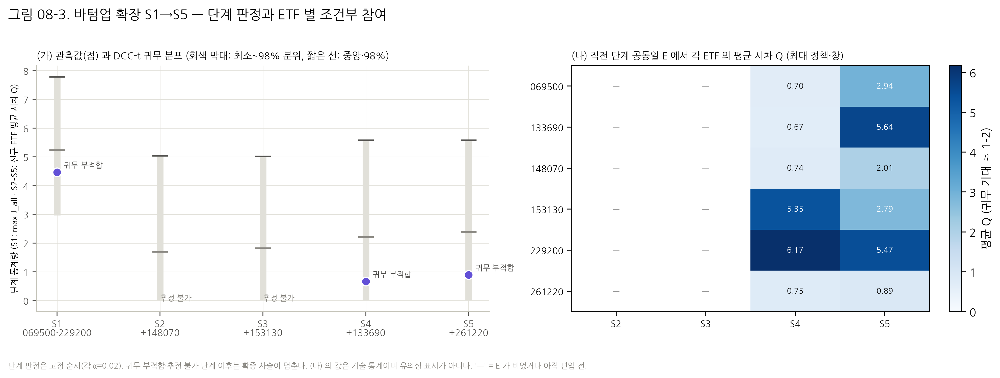

In [11]:
# 그림 08-3: 단계 통계량 vs DCC 귀무 분포 · ETF×단계 조건부 참여 강도
NULL_DCC = np.load(ROOT / "outputs/t15/mc/null_eval_dcc.npz")  # DCC 귀무 평가 50,000 반복
NC = {"S1": NULL_DCC["M_subset"][:, 0], **{f"S{k + 2}": NULL_DCC["C_stage"][:, k] for k in range(4)}}  # 단계별 귀무
PART = A.participation_table(OBS)  # 기술 통계
save_csv(PART, "stage_participation.csv")  # 근거
P3 = F.fig_bottom_up(STAGE, NC, PART, FIG, "08-3")  # 바텀업 그림
display(Image(filename=str(P3[0]), width=950))  # 렌더 확인

**해석 (07–09).**
- **S1 (KOSPI200·KOSDAQ150).**
  - 관측 M_S1 = 4.471, DCC-t p = 0.853 이다. CCC-t 는 0.845, H0-A 는 원형 이동 0.627 · 블록 0.602 다.
  - 069500 이 귀무 적합도 N3 에서 탈락해 판정은 `NULL_MODEL_INVALID` 다. r² 자기상관이 5개 연도 모형 중 4개에서 envelope 위였다.
  - 사전 규칙에 따라 **확증 사슬은 S1 에서 멈춘다**. 공개 진행표에 "S2 에서 멈춘다" 고 적었던 예측은 이 결과로 정정한다. 규칙은 바꾸지 않았다.
  - 적합도를 무시하더라도 p 는 기준 0.02 에서 멀다.
- **공동 극단이 없었다.**
  - S1 의 일별 J_all 최대값은 4.471 이고, c_E = −log 0.01 = 4.605 에 못 미친다. 2021–2025 에 두 ETF 가 ±2일 안에서 동시에 각자 귀무 꼬리 1% 에 들어간 날이 하루도 없었다는 뜻이다.
  - 그래서 E₁ 이 비어 S2·S3 조건부 참여는 `NOT_ESTIMABLE` 이다. 이는 "국채·단기채가 참여하지 않았다" 는 증거가 **아니다**.
- **S4·S5.**
  - C_S4 = 0.669 (p = 0.855), C_S5 = 0.893 (p = 0.953) 이다.
  - 구성원 적합도 탈락과 사슬 중단으로 확증 지위가 없다.
- **조건부 귀무 유효성.**
  - V1·V2 처럼 앞 단계만 실제로 변할 때, 신규 ETF 검정의 기각률은 0.007–0.027 이었다.
  - Wilson 하한이 모두 0.02 이하라 조건부 귀무는 성립했다. 따라서 무효 판정의 원인은 조건부 귀무가 아니라 주변 적합도다.
- **G7 답.**
  - Q1 공동 반응: KOSPI–KOSDAQ 공동 CUSUM 극단은 관측되지 않았다.
  - Q2·Q3 이례성: H0-A·H0-B 모두 비이례적이다 (p ≥ 0.60). 단 H0-B 는 확증 불가다.
  - Q4 국채10년의 추가 정보: 추정 불가.
  - Q5 단기채: 귀무 부적합.
  - Q6 나스닥·Q7 원유: 비유의이며 확증 불가.

## 10. 전체 57개 부분집합

**검정 통계량.**
- M_S = max_{p,w,t} J_all(S) 다. 정책·창·날짜·시차 탐색은 귀무 반복에서 똑같이 수행한다.
- J_2(S) 는 기술용이다. 상위 집합의 J_2 는 가장 강한 쌍이 정하기 때문이다.

**다중검정.**
- 57개에 Holm α=0.02 를 적용하고, 민감도로 Westfall–Young minP 를 본다.
- 가족 해상도 규칙: B × 0.02/57 ≥ 10. DCC 50,000 이면 17.5 다.
- 153130 이나 148070 이 들어간 부분집합은 귀무 적합도에 따라 확증에서 빠질 수 있다.
- 같은 사건이 주 경로와 부분집합에 다시 나타나도 독립 증거가 아니다.

,family,B,strictest,B_x_strictest,ok
0,secondary_57,50000,0.000351,17.54386,True


status
NULL_MODEL_INVALID    56
NOT_SIGNIFICANT        1
Name: 부분집합 수, dtype: int64

,subset,M_obs,p_dcc_label,p_dcc_ci99_low,p_dcc_ci99_high,h0b_valid,holm_status,status,p_minp_adjusted,p_ccc,p_h0a_circular_shift_within_year
23,069500+153130+261220,4.581972,0.04024,0.037991,0.042537,False,NULL_MODEL_INVALID,NULL_MODEL_INVALID,NaN,0.037193,0.038696
13,153130+261220,5.688659,0.09526,0.091887,0.098670,False,NULL_MODEL_INVALID,NULL_MODEL_INVALID,NaN,0.087383,0.137586
51,069500+229200+148070+153130+261220,2.979389,0.1139,0.110267,0.117606,False,NULL_MODEL_INVALID,NULL_MODEL_INVALID,NaN,0.106779,0.028297
36,069500+229200+148070+133690,3.594493,0.1237,0.119914,0.127518,False,NULL_MODEL_INVALID,NULL_MODEL_INVALID,NaN,0.113577,0.029397
34,153130+133690+261220,4.043095,0.1288,0.124947,0.132684,False,NULL_MODEL_INVALID,NULL_MODEL_INVALID,NaN,0.116177,0.123288
6,229200+153130,5.346670,0.1702,0.165873,0.174550,False,NULL_MODEL_INVALID,NULL_MODEL_INVALID,NaN,0.170166,0.028697
31,148070+153130+133690,3.902867,0.1756,0.171199,0.179983,False,NULL_MODEL_INVALID,NULL_MODEL_INVALID,NaN,0.173765,0.078692
49,148070+153130+133690+261220,3.138802,0.2001,0.195490,0.204727,False,NULL_MODEL_INVALID,NULL_MODEL_INVALID,NaN,0.195961,0.081692
18,069500+229200+261220,4.262008,0.2061,0.201439,0.210777,False,NULL_MODEL_INVALID,NULL_MODEL_INVALID,NaN,0.186163,0.148985
15,069500+229200+148070,4.182862,0.21,0.205306,0.214709,False,NULL_MODEL_INVALID,NULL_MODEL_INVALID,NaN,0.207958,0.062194


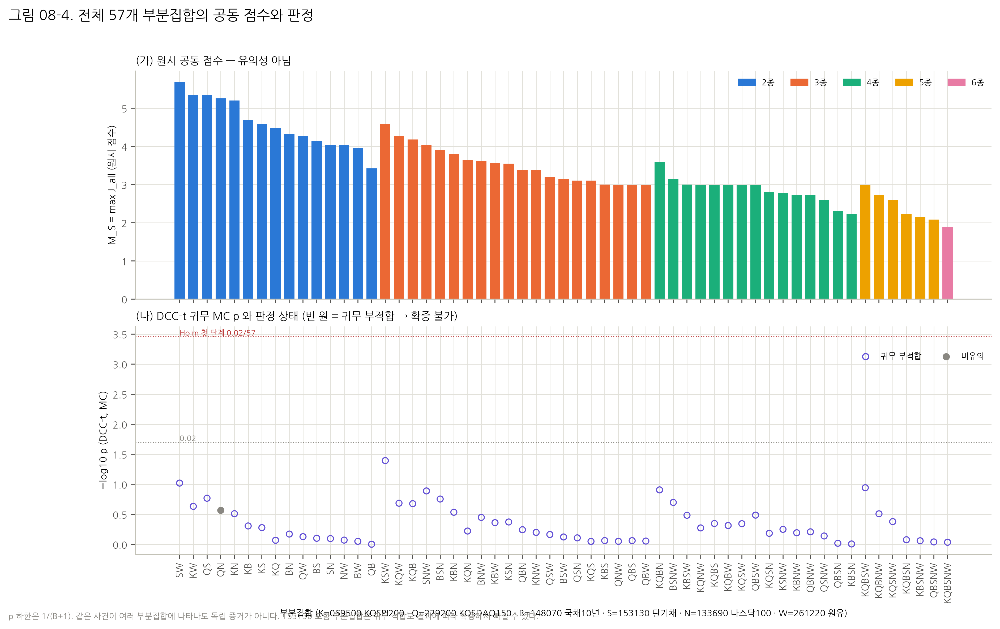

In [12]:
# 57개 부분집합 판정표와 그림 08-4 (원시 점수와 판정을 다른 패널에)
SUB = TESTS["subset"]  # 57행
save_csv(SUB, "subset57_tests.csv")  # 근거
save_csv(TESTS["family_resolution_ok"], "family_resolution.csv")  # 가족 해상도
assert len(SUB) == 57 and SUB.subset.is_unique  # 누락·중복 없음
display(TESTS["family_resolution_ok"])  # B×기준
display(SUB.status.value_counts().rename("부분집합 수"))  # 상태 분포
display(SUB.sort_values("p_dcc").head(12)[["subset", "M_obs", "p_dcc_label", "p_dcc_ci99_low", "p_dcc_ci99_high", "h0b_valid", "holm_status", "status", "p_minp_adjusted", "p_ccc", "p_h0a_circular_shift_within_year"]])  # p 하위 12
P4 = F.fig_subsets(SUB, FIG, "08-4")  # 57개 그림
display(Image(filename=str(P4[0]), width=950))  # 렌더 확인

**해석 (10).**
- **판정 분포.** 57개 중 56개가 `NULL_MODEL_INVALID` 이다. 069500·148070·153130·261220 중 하나라도 들어가 있거나, 069500+148070 쌍이 N4 에서 탈락했기 때문이다.
- **유효한 부분집합.** H0-B 가 유효한 부분집합은 **229200+133690 하나**다.
  - p = 0.270, CCC-t 0.255, minP 조정 0.270 으로 `NOT_SIGNIFICANT` 다.
- **원시 p.** 무효를 무시하고 본 DCC-t 원시 p 의 최소값도 0.040 이다 (069500+153130+261220). Holm 의 가장 엄격한 기준 0.02/57 = 3.5e-4 보다 백 배 이상 크다.
- **MC 해상도.** 가족 해상도 B × 기준 = 17.5 로 규칙(≥ 10)을 충족했다. 그래서 `INSUFFICIENT_MONTE_CARLO` 판정은 없고, 연장 규칙도 쓰지 않았다.
- **원시 점수.** 원시 공동 점수 최대는 153130+261220 의 5.689 다. 원시 점수가 높다는 것과 유의하다는 것은 다르다.
- **G7 Q8 (주 경로 밖 부분집합의 공통성).** 귀무를 넘는 공통성은 확인되지 않았다.

## 11–12. H0-A 시간 정렬 귀무 · H0-B DCC-t / CCC-t 귀무

**H0-A (보조).**
- ETF·연도마다 변환 하나를 뽑는다. 원형 이동과 블록 20의 원형 블록 재표집, 두 방법이다.
- 그 변환을 그 ETF-연도의 세 정책·네 창 유효 구간에 똑같이 적용한다. `NOT_AVAILABLE` 구간은 그대로 둔다.
- 두 방법을 합산하지 않는다. **두 방법이 모두 기각할 때만** H0-A 기각으로 본다 (보수적 규칙, H0-A 계산 전에 고정).
- H0-A 는 상대적 시간 정렬의 이례성을 본다. 공통 시장 요인을 보존하지 않는다.

**H0-B (주).**
- 평가연도 y 마다 **y 이전 수익률로만** GARCH(1,1)-t 주변 + DCC(1,1)-t 결합을 적합한다.
- 반복마다 model_y 로 2019..y 경로를 실제 날짜 위에 모의하고, 연간 SVR 재적합부터 공동 통계량까지 전 과정을 반복한다.
- CCC-t 는 같은 시드(공통 난수)로 돌린 민감도다. DCC 가 부적합해도 CCC 로 대체하지 않는다.

**적합도 게이트.**
- N1 수치: 어느 해든 실패하면 해당 ETF 또는 전체가 무효다.
- N3 ETF 별: 첨도·r² 자기상관·분산·정확 0 비율·LB(z, z²).
- N4 쌍별: 상관·하위 5% 동시 초과·60일 상관 sd.
- N3·N4 는 연도 모형마다 관측(자료 < y) 을 모의 envelope 0.5–99.5% 와 비교하고, 5개 연도 중 2개 이상 벗어나면 탈락이다.
- N5 (주변 CUSUM 본체) 는 진단만 한다.

,model,year,check,ok
179,DCC,2024,margin2_interior,False
208,CCC,2024,margin2_interior,False


,ticker,N1_margin_ok_all_years,kurt_years_outside,acf_r2_years_outside,var_years_outside,zero_share_years_outside,lb10_z_p_years_below_0.01,lb10_z2_p_years_below_0.01,N3_pass
0,069500,True,-,"2021,2022,2023,2024",-,-,-,-,False
1,229200,True,-,-,-,-,-,-,True
2,148070,False,-,-,-,-,2024,-,False
3,153130,True,2025,-,-,"2021,2022,2023,2024,2025","2021,2022,2023,2024,2025",-,False
4,133690,True,-,-,-,-,-,-,True
5,261220,True,"2021,2022,2023,2024,2025",-,-,-,-,-,False


,pair,corr_years_outside,coexceed_years_outside,rollcorr_sd_years_outside,N4_fail_count,N4_pass
0,069500+229200,2022,"2021,2022,2023,2024",-,1,True
1,069500+148070,-,"2021,2022","2021,2022,2023,2024,2025",2,False
2,069500+153130,-,-,2025,0,True
3,069500+133690,-,-,-,0,True
4,069500+261220,-,-,-,0,True
5,229200+148070,-,2021,"2021,2022,2023,2024,2025",1,True
6,229200+153130,-,-,"2024,2025",1,True
7,229200+133690,-,-,-,0,True
8,229200+261220,-,-,-,0,True
9,148070+153130,-,-,-,0,True


,statistic,year_model,ticker,obs,null_median,lo_0.5%,hi_99.5%,side
5,kurt,2021,261220,28.0233,2.6272,0.3501,21.2066,위
11,kurt,2022,261220,32.9577,2.3607,0.4657,19.3566,위
17,kurt,2023,261220,28.7050,2.5251,0.5065,28.1156,위
23,kurt,2024,261220,30.0515,2.3789,0.6178,24.3637,위
27,kurt,2025,153130,296.8434,5.7644,1.2679,82.7616,위
29,kurt,2025,261220,32.3929,2.5228,0.8411,24.3862,위
30,acf_r2,2021,069500,0.4225,0.1166,0.0129,0.3389,위
36,acf_r2,2022,069500,0.4156,0.1419,0.0445,0.3558,위
42,acf_r2,2023,069500,0.3958,0.1408,0.0450,0.3493,위
48,acf_r2,2024,069500,0.3858,0.1321,0.0469,0.3463,위


H0-B 유효 단계: [] | 유효 부분집합: 1 / 57


,median_inside,iqr_inside
ticker,,
069500,1.000000,1.000000
133690,1.000000,1.000000
148070,1.000000,1.000000
153130,0.833333,0.916667
229200,1.000000,1.000000
261220,0.916667,1.000000


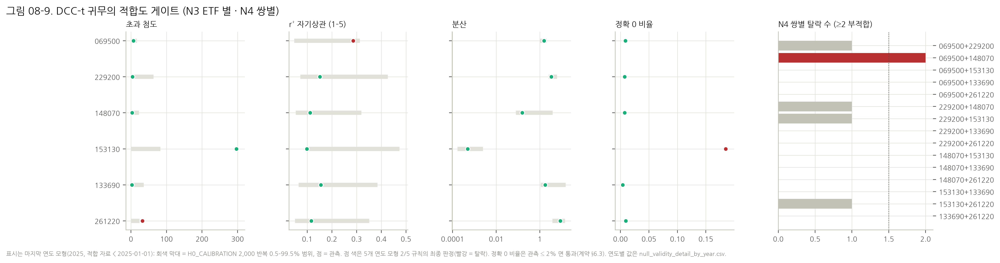

In [13]:
# 귀무 적합도 표 (N1 연도별 실패 · N3 · N4 · LB) 와 그림 08-9
N1 = VAL["n1"]  # 연도·모형·항목별
save_csv(N1, "null_validity_N1.csv")  # 근거
save_csv(VAL["n3"], "null_validity_N3.csv")  # 근거
save_csv(VAL["n4"], "null_validity_N4.csv")  # 근거
save_csv(VAL["lb"], "null_validity_ljungbox.csv")  # 근거
display(N1[~N1.ok])  # 실패 항목만
display(VAL["n3"][["ticker", "N1_margin_ok_all_years", "kurt_years_outside", "acf_r2_years_outside", "var_years_outside", "zero_share_years_outside", "lb10_z_p_years_below_0.01", "lb10_z2_p_years_below_0.01", "N3_pass"]])  # ETF 별
display(VAL["n4"][["pair", "corr_years_outside", "coexceed_years_outside", "rollcorr_sd_years_outside", "N4_fail_count", "N4_pass"]])  # 쌍별
VDET = A.validity_detail(OBS)  # 연도별 관측·envelope·방향
save_csv(VDET, "null_validity_detail_by_year.csv")  # 근거
display(VDET[(VDET.side != "안") & ~((VDET.statistic == "zero_share") & (VDET.obs <= 0.02))].round(4))  # 실제 탈락에 쓰인 이탈만
print("H0-B 유효 단계:", [k for k, v in VAL["valid_stage"].items() if v], "| 유효 부분집합:", sum(VAL["valid_subset"].values()), "/ 57")  # 요약
N5 = A.n5_marginal(OBS)  # 주변 CUSUM 본체 진단
save_csv(N5, "null_diagnostic_N5_marginal_cusum.csv")  # 근거
display(N5.groupby("ticker")[["median_inside", "iqr_inside"]].mean())  # 칸 비율
P9 = F.fig_validity(VAL["n3"].rename(columns=lambda c: c.replace("_last", "")), VAL["n4"], FIG, "08-9")  # 적합도 그림 (마지막 연도 모형 기준 표시)
display(Image(filename=str(P9[0]), width=950))  # 렌더 확인

,method,reps,unique_transforms,mean_junctions,allowed_shifts_per_etf_year_w20_to_w120,year_boundary
0,circular_shift_within_year,10000,10000,119.3286,w20:223–229; w30:213–219; w60:183–189; w120:12...,변환은 연도 안에서만 (경계 넘지 않음)
1,circular_block_bootstrap_within_year,10000,10000,1187.3345,w20:223–229; w30:213–219; w60:183–189; w120:12...,변환은 연도 안에서만 (경계 넘지 않음)


burn2000               burn500              
quantile      0.50   0.90   0.98    0.50   0.90   0.98
statistic                                             
C_S2         1.627  3.372  5.592   1.699  3.427  5.049
C_S3         1.724  3.240  5.188   1.829  3.453  5.016
C_S4         2.204  4.017  5.875   2.221  3.977  5.583
C_S5         2.299  3.972  5.460   2.397  4.014  5.584
M_S1         5.231  6.562  7.789   5.237  6.605  7.790

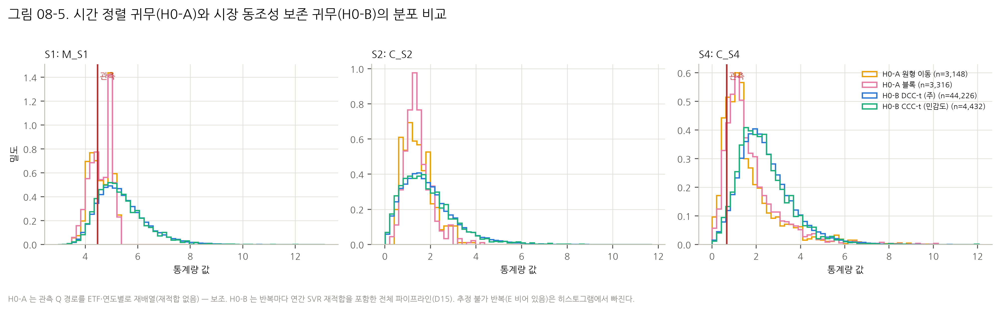

In [14]:
# H0-A 진단 · 초기조건 민감도 · 귀무 분포 비교 그림 08-5
H0AD = A.h0a_diagnostics(OBS)  # 접합부·허용 이동·중복
save_csv(H0AD, "h0a_diagnostics.csv")  # 근거
display(H0AD)  # 표
ROB = A.robustness_compare(OBS)  # 초기조건 burn-in 500 대 2000 비교
save_csv(ROB, "robustness_burnin.csv")  # 근거
display(ROB.pivot_table(index="statistic", columns="quantile", values=["burn500", "burn2000"]).round(3))  # 분위 비교
NULL_CCC = np.load(ROOT / "outputs/t15/mc/null_eval_ccc.npz")  # CCC 5,000 (같은 시드)
H0A = {m: np.load(ROOT / f"outputs/t15/mc/h0a_{m}.npz") for m in CFG["null_models"]["H0A"]["methods"]}  # H0-A 두 방법
st_obs = STAGE.set_index("stage").obs  # 관측 단계 통계량
NULLS = {}  # 통계량별 귀무 묶음
for name, key, k in (("S1: M_S1", "M_subset", 0), ("S2: C_S2", "C_stage", 0), ("S4: C_S4", "C_stage", 2)):  # 대표 세 통계량
    NULLS[name] = {"H0-A 원형 이동": H0A["circular_shift_within_year"][key][:, k], "H0-A 블록": H0A["circular_block_bootstrap_within_year"][key][:, k], "H0-B DCC-t (주)": NULL_DCC[key][:, k], "H0-B CCC-t (민감도)": NULL_CCC[key][:, k]}  # 네 분포
P5 = F.fig_nulls({"S1: M_S1": st_obs["S1"], "S2: C_S2": st_obs["S2"], "S4: C_S4": st_obs["S4"]}, NULLS, FIG, "08-5")  # 비교 그림
display(Image(filename=str(P5[0]), width=950))  # 렌더 확인

**해석 (11–12).**
- **귀무 적합도: 탈락은 모두 "관측이 귀무보다 크다" 쪽이다.**
  - 069500: r² 자기상관 0.386–0.423 (2021–2024 모형). 귀무 상한은 ≤ 0.359 다. 실제 변동성 군집이 GARCH(1,1)-t 모의보다 강하다.
  - 261220: 초과 첨도 28.0–33.0 (5/5 모형). 주변 ν 는 4.4–7.5 인데 결합 다변량 t 의 ν 는 약 8 이라 모의 꼬리가 얇아진다. 단일 자유도 DCC-t 설계의 한계다. **다른 결합 분포를 사후에 시도하지 않는다.**
  - 153130: 정확 0 비율 0.185–0.270, LB(z) p < 0.01 이 5/5 다. 연속분포 귀무로 재현되지 않는다.
  - 148070: 2024 모형의 지속성이 경계값이다 (N1).
  - 229200·133690 은 모두 통과했다.
- **H0-A (보조).**
  - S1 은 0.627 (원형 이동) · 0.602 (블록) 이다.
  - 부분집합의 H0-A 최소값은 0.028 · 0.024 로, 0.02/57 보다 훨씬 크다. 그래서 `SIGNIFICANT_H0A_ONLY` 도 없다.
  - 변환은 방법마다 10,000개가 모두 서로 달랐다.
- **CCC-t (민감도).** DCC 와 거의 같다 (S1 0.845 대 0.853). 동적 상관을 넣어도 결론은 바뀌지 않는다.
- **초기조건 민감도.** burn-in 500 대 2000 의 M_S1 98% 분위가 7.790 대 7.789 로 안정적이었다.

## 13. 합성 검정력·오경보

**설계.**
- 모든 반복에서 연간 SVR 재적합을 포함한다.
- 변화 연도는 균등하게 뽑고, 연중 위치는 130–170, 지속은 연말까지다. 분산 배율은 ×2 / ×0.5 다.

| 시나리오 | 내용 | 목표 |
|---|---|---|
| V1 | 069500·229200 동시 ×2 | S1 |
| V2 | V1 + 148070 ×2 | S1·S2 |
| V3_d1·d3·d5 | V1 + 148070 이 1·3·5일 늦게 ×2 | S2 (J_all) |
| V4 | 148070·133690 만 ×2 | 부분집합 |
| V5 | S1 ×2, 148070 ×0.5 | S1·S2 |
| V6 | 분산 불변, 상관만 max(Q̄, 0.7) | S1·S5 |
| V7 | 정상 공통 충격 −6σ 하루 (모수 불변) | **음성 대조** |

**조건부 귀무 유효성.**
- V1 은 앞 단계(S1)만 실제로 변하고 S2–S5 의 신규 ETF 는 변하지 않는 상황이다. 이때 C_Sk 의 기각률이 α=0.02 를 넘지 않아야 한다.
- V2 에서는 S3–S5 를 같은 방식으로 본다.

**검출률.** 분모는 **전체 반복**이다. 검출된 반복만 따로 세지 않는다.

**크기.**
- holdout 귀무 1,000 반복을 관측처럼 판정해 실제 크기를 잰다.
- 단기 q 후보·E(h)·개별 CUSUM 의 첫 반응 지연도 같은 반복에서 잰다.

,test,rejections,R,size,wilson_low,wilson_high,nominal,within
0,"S1 (M_S1, α=0.02)",24,1000,0.024,0.016180,0.035463,0.02,True
1,"S2 조건부 참여 (α=0.02, 추정 불가 반복은 비기각)",22,1000,0.022,0.014573,0.033086,0.02,True
2,"S3 조건부 참여 (α=0.02, 추정 불가 반복은 비기각)",17,1000,0.017,0.010641,0.027056,0.02,True
3,"S4 조건부 참여 (α=0.02, 추정 불가 반복은 비기각)",30,1000,0.030,0.021094,0.042503,0.02,False
4,"S5 조건부 참여 (α=0.02, 추정 불가 반복은 비기각)",14,1000,0.014,0.008358,0.023362,0.02,True
5,부분집합 57 Holm 가족 (FWER α=0.02),20,1000,0.020,0.012984,0.030690,0.02,True


,scenario,R,path_S1_reject,path_S2_cond_reject,path_S3_cond_reject,path_S4_cond_reject,path_S5_cond_reject,participation_recall,over_participation
0,V1,300,0.043,0.007,0.027,0.023,0.023,0.565,0.532
1,V2,300,0.017,0.013,0.017,0.023,0.020,0.570,0.530
2,V3_d1,300,0.027,0.013,0.003,0.023,0.010,0.576,0.530
3,V3_d3,300,0.033,0.030,0.020,0.007,0.030,0.567,0.517
4,V3_d5,300,0.040,0.037,0.017,0.013,0.023,0.613,0.528
5,V4,300,0.013,0.027,0.030,0.010,0.020,0.562,0.552
6,V5,300,0.040,0.027,0.020,0.023,0.020,0.613,0.526
7,V6,300,0.013,0.030,0.040,0.023,0.037,0.527,NaN
8,V7,300,0.030,0.017,0.050,0.030,0.030,NaN,0.510


,scenario,family,R,detected_60,detected_60_wilson_low,detected_60_wilson_high,detected_within_5,detected_within_20,median_delay_detected,false_sig_before_tau,ep_start_err_median,ep_end_err_median
0,V1,S1,300,0.000,0.000,0.013,0.000,0.000,NaN,0.030,NaN,NaN
1,V2,S1,300,0.000,0.000,0.013,0.000,0.000,NaN,0.003,NaN,NaN
2,V2,S2,300,0.000,0.000,0.013,0.000,0.000,NaN,0.000,NaN,NaN
3,V3_d1,S2,300,0.000,0.000,0.013,0.000,0.000,NaN,0.000,NaN,NaN
4,V3_d3,S2,300,0.000,0.000,0.013,0.000,0.000,NaN,0.003,NaN,NaN
5,V3_d5,S2,300,0.000,0.000,0.013,0.000,0.000,NaN,0.000,NaN,NaN
6,V4,subset:148070+133690,300,0.000,0.000,0.013,0.000,0.000,NaN,0.000,NaN,NaN
7,V5,S1,300,0.000,0.000,0.013,0.000,0.000,NaN,0.020,NaN,NaN
8,V5,S2,300,0.000,0.000,0.013,0.000,0.000,NaN,0.000,NaN,NaN
9,V6,S1,300,0.000,0.000,0.013,0.000,0.000,NaN,0.003,NaN,NaN


,scenario,signal,n_affected_etf_reps,detected_60,median_delay,null_detected_60,null_median_delay,n
0,V1,cusum_Q_A_w120,600,0.075,29.0,0.038,16.0,600.0
1,V1,cusum_Q_A_w20,600,0.233,29.5,0.228,26.0,600.0
2,V1,cusum_Q_A_w30,600,0.190,17.0,0.150,21.0,600.0
3,V1,cusum_Q_A_w60,600,0.110,17.0,0.077,26.0,600.0
4,V1,cusum_Q_B_w120,600,0.048,25.0,0.025,22.0,600.0
5,V1,cusum_Q_B_w20,600,0.205,31.0,0.240,23.5,600.0
6,V1,cusum_Q_B_w30,600,0.175,20.0,0.132,25.0,600.0
7,V1,cusum_Q_B_w60,600,0.095,18.0,0.057,20.0,600.0
8,V1,cusum_Q_base_w120,600,0.072,20.0,0.063,22.5,600.0
9,V1,cusum_Q_base_w20,600,0.207,24.0,0.232,24.0,600.0


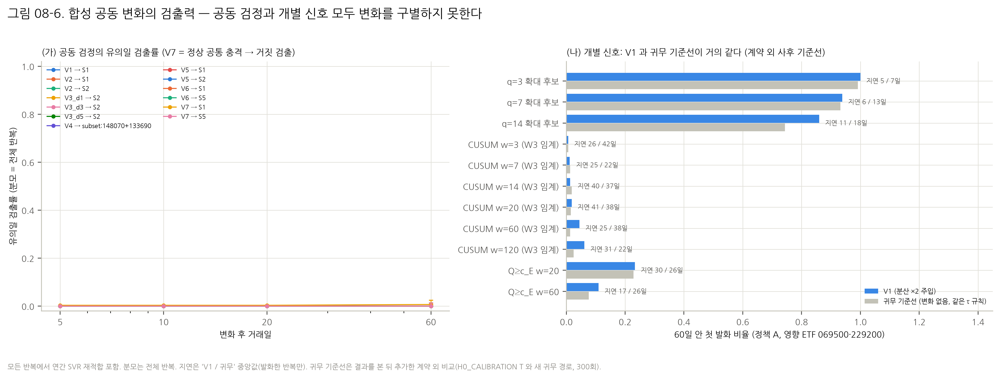

In [15]:
# 실제 크기 (holdout) · 경로 수준 판정 · 유의일 검출률 · 지연 · 그림 08-6
SIZE = A.size_check(OBS)  # holdout 1,000 → 실제 크기
save_csv(SIZE, "size_check_holdout.csv")  # 근거
display(SIZE)  # 크기
for k in ("path", "detection", "delays", "criticals"):  # 네 표
    save_csv(POWER[k], f"power_{k}.csv")  # 근거
display(POWER["path"].round(3))  # 시나리오별 경로 수준 기각률·참여
display(POWER["detection"][["scenario", "family", "R", "detected_60", "detected_60_wilson_low", "detected_60_wilson_high", "detected_within_5", "detected_within_20", "median_delay_detected", "false_sig_before_tau", "ep_start_err_median", "ep_end_err_median"]].round(3))  # 검출
BASE_FIRE = A.null_first_fire_baseline(OBS, 300)  # 계약 외 사후 기준선: 변화 없는 귀무의 60일 첫 발화
save_csv(BASE_FIRE, "null_first_fire_baseline_posthoc.csv")  # 근거
V1D = POWER["delays"][POWER["delays"].scenario.eq("V1")].merge(BASE_FIRE, on="signal", how="left")  # V1 대 귀무 (세 정책 모두)
save_csv(V1D, "v1_vs_null_first_fire.csv")  # 근거
display(V1D[V1D.signal.str.contains("q3|q7|q14|w3crit|cusum_Q")].round(3))  # 세 정책 비교표
P6 = F.fig_power(POWER["detection"], POWER["delays"], BASE_FIRE, FIG, "08-6")  # 검정력 그림 (귀무 기준선 포함)
display(Image(filename=str(P6[0]), width=950))  # 렌더 확인

**해석 (13) — 이 연구의 결론을 정하는 장.**
- **크기는 맞다.** holdout 1,000 회의 실제 기각률은 다음과 같다.
  - S1 0.024 [0.016, 0.036], S2 0.022, S3 0.017, S5 0.014, 부분집합 Holm 가족 FWER 0.020 [0.013, 0.031] 이다.
  - S4 만 0.030 [0.021, 0.043] 으로 약간 반보수적이다. 6개 중 하나이며, 규칙은 바꾸지 않는다.
- **검출력은 사실상 없다.**
  - V1 은 KOSPI200·KOSDAQ150 분산 ×2 를 연말까지 지속시킨 시나리오다. 여기서 S1 경로 수준 기각률은 **0.043** 으로, 크기와 거의 같다.
  - 모든 대립 시나리오에서 유의일 검출은 **0/300** 이다. 예외는 V7 의 S1 거짓 검출 2/300 = 0.007 뿐이다.
  - 영향 ETF 의 참여율은 0.565, 비영향 ETF 의 과잉 참여는 0.532 로 거의 같다. 주입한 변화가 잔차 CUSUM 에서 보이지 않는다.
- **개별 신호도 변화를 구별하지 못한다.** V1 과 귀무 기준선의 60일 첫 발화 비율을 비교했다 (계약 외 사후 기준선).
  - q=3 확대 후보 1.000 대 0.992
  - q=14 확대 후보 0.860 대 0.743
  - CUSUM Q ≥ c_E (w=20) 0.233 대 0.228
  - W3 임계 CUSUM (w=60) 0.045 대 0.013
- **원인 해석.**
  - SVR–GARCH 예측분산이 분산 상승을 빠르게 흡수한다. 그래서 표준화 잔차의 CUSUM 은 지속 분산 변화에 거의 반응하지 않는다.
  - 여기에 정책 3 × 창 4 × 날짜 × 시차 ±2 를 최대값으로 탐색하는 보정 부담이 더해진다.
  - T12 (정책 A 검정력 0.085) 와 W1 (60일 검출 0.03–0.10) 의 낮은 검출력을 W3 공동 검정이 그대로 물려받았다.
- **G7 Q11 (알려진 합성 변화에 대한 검출력).** 충분하지 않다.
  - 그러므로 실제 ETF 에서 유의 구간이 없었다는 사실로 "추가 공동 불안정성이 없었다" 고 결론내릴 수 없다.

## 14. 계층적 다중검정

**오류 예산.**
- 전체 α = 0.05 = 주 경로 0.020 + 부분집합 0.020 + 가격 예약 0.010 (사용하지 않음).

**고정 순서 절차의 오류 통제 전제.**
- 단계 k 의 검정은 단계 1..k−1 이 모두 기각됐을 때만 확증 지위를 갖는다. 각 단계 검정이 그 단계의 귀무에서 크기 ≤ α 이면 가족 FWER ≤ α 다.
- 각 단계 검정은 전체 무변화 DCC 귀무에서 크기를 맞췄다 (holdout 으로 확인).
- 그러나 "앞 단계가 실제로 변한" 부분 귀무에서는 크기가 보장되지 않는다. 그래서 13장의 조건부 귀무 유효성 검사로 따로 확인했다. 실패한 단계는 확증에서 뺀다.

**MC 정밀도.**
- 모든 p 에 Clopper–Pearson 99% 구간을 붙인다. 구간이 기준을 포함하면 `INSUFFICIENT_MONTE_CARLO` 다.
- 사전에 정한 연장 규칙(+25,000 회 1회, 24시간 예산 이내) 을 적용했는지 함께 기록한다.

In [16]:
# 다중검정 요약: 주 경로 사슬 · 부분집합 Holm · minP 민감도 · CCC 민감도 · 연장 규칙 적용 여부
MT = pd.DataFrame([{"family": "주 경로 S1–S5 (고정 순서 α=0.02)", "hypotheses": 5, "significant_h0b": int((STAGE.confirmatory_status == "SIGNIFICANT_H0B").sum()), "chain_stop_stage": next((s for s, c in zip(STAGE.stage, STAGE.confirmatory_status, strict=True) if c != "SIGNIFICANT_H0B"), "없음"), "insufficient_mc": int((STAGE.status == "INSUFFICIENT_MONTE_CARLO").sum())}, {"family": "부분집합 57 (Holm α=0.02)", "hypotheses": 57, "significant_h0b": int((SUB.status == "SIGNIFICANT_H0B").sum()), "chain_stop_stage": "—", "insufficient_mc": int((SUB.status == "INSUFFICIENT_MONTE_CARLO").sum())}])  # 가족 요약
EXT = json.loads((ROOT / "research/joint_cusum_w3/MC_EXTENSION_DECISION.json").read_text())  # 연장 규칙 판정 기록
MT["extension_rule"] = EXT["decision"]  # 적용 여부
save_csv(MT, "multiple_testing_summary.csv")  # 근거
display(MT)  # 표
display(SUB[SUB.p_minp_adjusted.notna()].sort_values("p_minp_adjusted").head(8)[["subset", "p_dcc", "p_minp_adjusted", "holm_status"]])  # minP 민감도

,family,hypotheses,significant_h0b,chain_stop_stage,insufficient_mc,extension_rule
0,주 경로 S1–S5 (고정 순서 α=0.02),5,0,S1,0,NOT_NEEDED
1,부분집합 57 (Holm α=0.02),57,0,—,0,NOT_NEEDED


,subset,p_dcc,p_minp_adjusted,holm_status
7,229200+133690,0.269755,0.269755,NOT_SIGNIFICANT


## 15. 공동 반응 구간 추출

**두 대상을 구분한다.**
- **공동 반응 날짜**: J_max(S,t) = max_{p,w} J_all 이 유의일 기준 이상인 날이다. S1 은 귀무 M_S1 의 98% 분위, 부분집합은 1−0.02/57 분위를 쓴다.
- **공동 반응 구간**: J_max ≥ c0 = −log 0.01 인 연속일이다. 비반응일은 건너뛰지 않는다.
  - 구간 수준 귀무 통계량은 누적 초과량 Σ(J_max − c0) 의 반복별 최대값이다.
  - 구간 경계와 지속의 유의성은 S1 에서만, 그리고 그 p ≤ 0.02 이고 S1 유의일 검정이 기각됐을 때만 주장한다.
  - 유의일이 하나 있다고 해서 구간 전체 경계가 유의한 것은 아니다.

**시점 필드.** `episode_start_at` · `episode_end_at` · `joint_anchor_at` (최대 점수일) · `joint_confirmed_at` (시차를 반영한 첫 이용 가능일) · `episode_confirmed_at` (끝 다음 거래일) · `retrospective_p_value` · `inference_completed_at`.

In [17]:
# 57개 집합의 탐색 구간 · 유의일 수 · 구간 수준 p · 판정 · 방향 (16장)
EP = A.direction(OBS, A.episodes(OBS, TESTS, VAL))  # 구간 + 방향
save_csv(EP, "joint_episodes.csv")  # 근거 (날짜·점수만, 가격 없음)
display(EP.groupby("size").agg(episodes=("subset", "size"), with_sig_days=("n_days_ge_day_critical", lambda s: int((s > 0).sum()))))  # 크기별
display(EP.day_level_status.value_counts().rename("구간 수 (유의일 판정)"))  # 상태
TOP = EP.sort_values("cumulative_excess", ascending=False).head(15)  # 누적 초과 상위
display(TOP[["subset", "episode_start_at", "episode_end_at", "joint_confirmed_at", "n_days", "max_J", "cumulative_excess", "n_days_ge_day_critical", "p_label", "day_level_status", "episode_level_status", "direction"]])  # 상위 구간

,episodes,with_sig_days
size,,
2,10,0


day_level_status
NULL_MODEL_INVALID    8
EXPLORATORY           2
Name: 구간 수 (유의일 판정), dtype: int64

,subset,episode_start_at,episode_end_at,joint_confirmed_at,n_days,max_J,cumulative_excess,n_days_ge_day_critical,p_label,day_level_status,episode_level_status,direction
8,153130+261220,2025-04-04,2025-04-08,2025-04-07,3,5.688659,3.183647,0,0.06648,NULL_MODEL_INVALID,EXPLORATORY,COMMON_EXPANSION
4,069500+261220,2021-06-14,2021-06-21,2021-06-15,6,5.346793,3.154273,0,0.1112,NULL_MODEL_INVALID,EXPLORATORY,COMMON_CONTRACTION
5,229200+153130,2023-09-08,2023-09-12,2023-09-08,3,5.346670,1.572488,0,0.146,NULL_MODEL_INVALID,EXPLORATORY,MIXED
9,153130+261220,2025-04-10,2025-04-11,2025-04-10,2,5.372141,1.369509,0,0.1544,NULL_MODEL_INVALID,EXPLORATORY,MIXED
6,229200+133690,2021-08-24,2021-08-24,2021-08-24,1,5.254494,0.649324,0,0.3498,EXPLORATORY,EXPLORATORY,UNDETERMINED
1,069500+133690,2021-02-26,2021-02-26,2021-03-02,1,5.203829,0.598658,0,0.3788,NULL_MODEL_INVALID,EXPLORATORY,UNDETERMINED
2,069500+133690,2025-12-22,2025-12-22,2025-12-22,1,5.085453,0.480283,0,0.4109,NULL_MODEL_INVALID,EXPLORATORY,COMMON_EXPANSION
7,229200+133690,2021-09-13,2021-09-13,2021-09-13,1,4.972764,0.367593,0,0.4262,EXPLORATORY,EXPLORATORY,UNDETERMINED
3,069500+261220,2021-06-04,2021-06-07,2021-06-08,2,4.741794,0.273248,0,0.4583,NULL_MODEL_INVALID,EXPLORATORY,COMMON_CONTRACTION
0,069500+148070,2021-10-27,2021-10-28,2021-10-29,2,4.689116,0.167892,0,0.4599,NULL_MODEL_INVALID,EXPLORATORY,MIXED


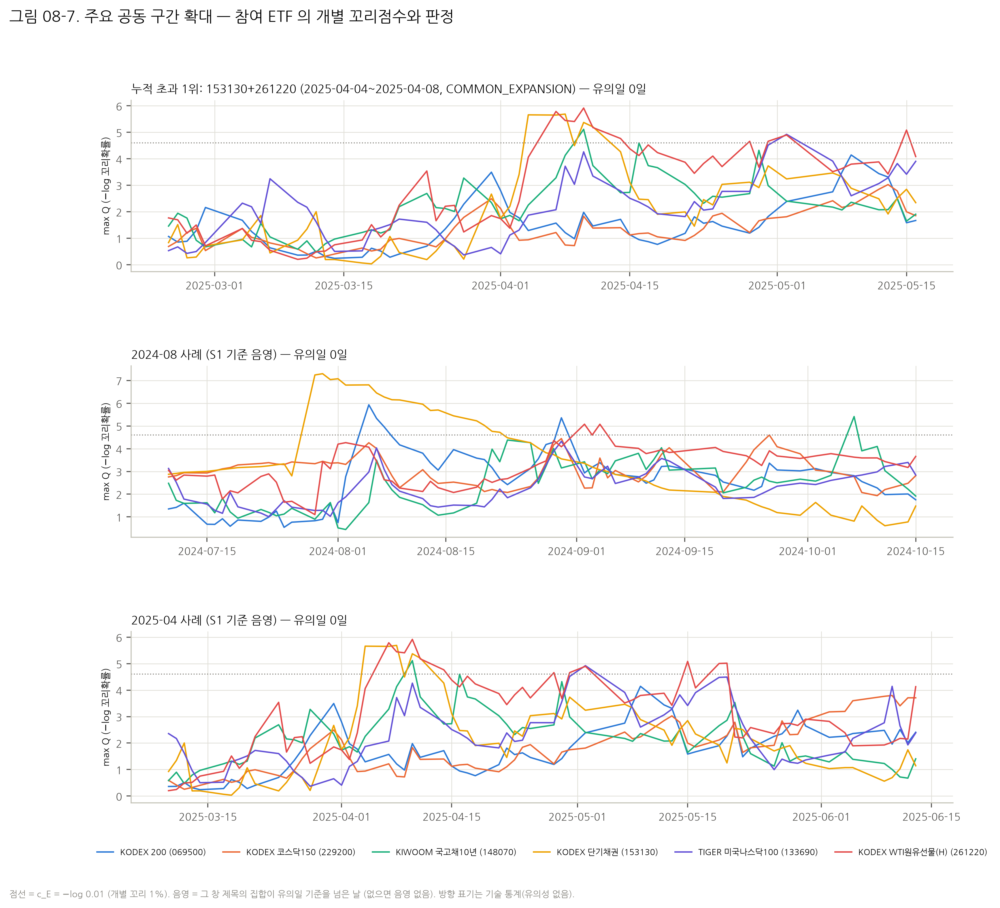

In [18]:
# 그림 08-7: 상위 공동 구간과 두 사례 창 확대 (유의일 음영은 그 집합이 유의일 기준을 넘은 날)
dates = OBS.dates  # 평가일
def sig_flag(subset):  # 집합의 유의일 플래그
    dj = DAILY[DAILY.subset == subset].set_index("date").reindex(dates)  # 일별 점수
    crit = EP[EP.subset == subset].day_critical.iloc[0] if (EP.subset == subset).any() else np.inf  # 유의일 기준
    return (dj.J_all_max >= crit).to_numpy()  # 플래그
top1 = TOP.iloc[0]  # 누적 초과 1위 구간
WIN = [(f"누적 초과 1위: {top1.subset} ({top1.episode_start_at}~{top1.episode_end_at}, {top1.direction})", str(pd.Timestamp(top1.episode_start_at) - pd.Timedelta(days=40))[:10], str(pd.Timestamp(top1.episode_end_at) + pd.Timedelta(days=40))[:10]), ("2024-08 사례 (S1 기준 음영)", "2024-07-10", "2024-10-15"), ("2025-04 사례 (S1 기준 음영)", "2025-03-10", "2025-06-15")]  # 세 창
SIGD = {WIN[0][0]: sig_flag(top1.subset), WIN[1][0]: sig_flag("069500+229200"), WIN[2][0]: sig_flag("069500+229200")}  # 음영
P7 = F.fig_episode_zoom(OBS, WIN, SIGD, NAMES, FIG, "08-7")  # 확대 그림
display(Image(filename=str(P7[0]), width=950))  # 렌더 확인

**해석 (15).**
- **탐색 구간.** J_max ≥ c0 = −log 0.01 인 탐색 구간은 57개 집합 전체에서 **10개뿐이고 모두 2종 쌍**이다.
  - S1 (069500+229200) 의 구간은 0개다.
  - 유의일 기준을 넘은 날은 **0일**이다.
- **구간 수준 p.** 최소값은 0.066 이다 (153130+261220, 2025-04-04~04-08, 누적 초과 3.18).
- **판정.** 8개는 귀무 부적합 집합의 구간이다. 유효 집합 229200+133690 의 2개 구간(2021-08-24, 2021-09-13)은 `EXPLORATORY` 다.
- **결론.** 유의한 공동 구간은 없다. 따라서 구간 경계·지속에 관한 유의성 주장도 없다.

## 16. 공통 구간의 확대·축소 방향

- CUSUM-of-squares 는 방향을 주지 않는다. 그래서 구간 e² 평균을 직전 60 평가일 e² 평균으로 나눈 비율로 방향을 판정한다 (최대 점수 정책).
  - ≥ 1.25 는 확대, ≤ 0.8 은 축소다.
  - 구성원 판정이 모두 같으면 공동 확대·공동 축소, 섞이면 혼합, 아니면 판정 불가다.
- 전후 구간을 CUSUM 극대점 기준으로 고르므로 사후 선택 편향이 있다. **방향에는 유의성을 주장하지 않는다.**
- H5 보조 진단으로 구간 전후 60일 수익률 상관 변화를 기술한다 (보정 없음).

In [19]:
# 방향 분포 (크기·유의 판정별) 와 H5 상관 변화 기술
display(pd.crosstab(EP["size"], EP.direction))  # 크기별 방향
display(pd.crosstab(EP.day_level_status, EP.direction))  # 판정별 방향
CORR = A.pair_correlation_shift(OBS, EP)  # 구간 전후 상관
save_csv(CORR, "h5_pair_correlation_shift.csv")  # 근거
display(CORR.groupby("pair").delta.describe()[["count", "mean", "50%"]].round(3))  # 쌍별 요약

direction,COMMON_CONTRACTION,COMMON_EXPANSION,MIXED,UNDETERMINED
size,,,,
2,2,2,3,3


direction,COMMON_CONTRACTION,COMMON_EXPANSION,MIXED,UNDETERMINED
day_level_status,,,,
EXPLORATORY,0,0,0,2
NULL_MODEL_INVALID,2,2,3,1


,count,mean,50%
pair,,,
069500+148070,1.0,-0.030,-0.030
069500+261220,2.0,-0.029,-0.029
153130+261220,2.0,0.259,0.259
229200+133690,2.0,0.156,0.156
229200+153130,1.0,0.094,0.094


**해석 (16).**
- **방향 분포.** 10개 탐색 구간의 방향은 혼합 3 · 판정 불가 3 · 공동 확대 2 · 공동 축소 2 였다.
- **G7 Q13 (공동 반응의 방향).**
  - 공동 반응의 방향은 한쪽으로 모이지 않는다.
  - 표본이 10개이고 귀무 보정이 없는 기술 통계이므로, 방향에 대한 주장은 하지 않는다.
- **H5 (구간 전후 60일 상관 변화).**
  - 쌍 8개의 평균 변화는 +0.105 다.
  - 보정되지 않은 탐색 결과다. 의존구조 자체의 변화를 검정한 것이 아니다.

## 17. 5·10·20일 가격 반응 (탐색, `EXPLORATORY_REUSED_DATA`)

- **기준일**: 공동 신호 이용 가능일(`joint_confirmed_at`) 종가의 다음 날부터 잰다. 기준 ETF 날짜를 매매 가능 시점으로 소급하지 않는다.
- **비교**: 단독 반응, 2종 이상 공동 반응, H0-B 유의 구간, 대조일.
  - 대조일은 같은 ETF·연도에서 그날의 사전 U_V(q=20) 십분위가 같고 ±20일 안에 후보가 없는 날이다. 매칭 변수는 그날까지의 정보만 쓴다.
- **결과 변수**: 누적 로그수익률, 나머지 5종 평균 대비 상대값, 경로 최대 상승·하락, 반전 비율.
- **추론**: 20일 날짜 블록 bootstrap 으로 한다. 겹친 사후 구간이 있으므로 iid t 검정은 쓰지 않는다.
- 2021–2025 는 이미 탐색한 자료다. 확증 검정은 미래 독립 자료에서 α=0.01 로 한다 (미사용). W2 의 −0.84%p 를 검증된 가설로 쓰지 않는다.

,group,h,n_events,n_date_blocks,median_ret,ci95_low,ci95_high,median_rel_vs_other5,share_up,reversal_share,label
0,control_for_single_etf_only,5,36,12,0.060,0.010,0.301,-0.047,0.722,NaN,EXPLORATORY_REUSED_DATA
1,control_for_single_etf_only,10,36,12,0.101,0.010,0.257,-0.275,0.694,NaN,EXPLORATORY_REUSED_DATA
2,control_for_single_etf_only,20,36,12,0.190,-0.034,0.263,1.630,0.611,NaN,EXPLORATORY_REUSED_DATA
3,control_for_two_or_more_etf,5,5,4,0.060,-3.173,4.126,2.678,0.600,NaN,EXPLORATORY_REUSED_DATA
4,control_for_two_or_more_etf,10,5,4,0.104,-6.107,6.200,4.738,0.800,NaN,EXPLORATORY_REUSED_DATA
5,control_for_two_or_more_etf,20,5,4,0.190,-7.103,7.880,2.507,0.800,NaN,EXPLORATORY_REUSED_DATA
6,single_etf_only,5,94,41,0.024,-0.356,0.065,-0.834,0.532,0.351,EXPLORATORY_REUSED_DATA
7,single_etf_only,10,93,41,0.106,0.005,0.206,-0.893,0.613,0.333,EXPLORATORY_REUSED_DATA
8,single_etf_only,20,91,40,0.163,-0.126,0.319,-0.872,0.604,0.341,EXPLORATORY_REUSED_DATA
9,two_or_more_etf,5,20,7,0.277,-1.567,1.657,-1.062,0.750,0.500,EXPLORATORY_REUSED_DATA


,group,h,observed_mean_diff,pooled_sd,n_per_group_required_alpha_0.01_power_0.8,note
0,two_or_more_etf,5,0.542,2.498,497.0,효과크기는 탐색 자료에서 추정 — 낙관적일 수 있다
1,two_or_more_etf,10,0.633,3.623,765.0,효과크기는 탐색 자료에서 추정 — 낙관적일 수 있다
2,two_or_more_etf,20,0.105,4.677,46027.0,효과크기는 탐색 자료에서 추정 — 낙관적일 수 있다


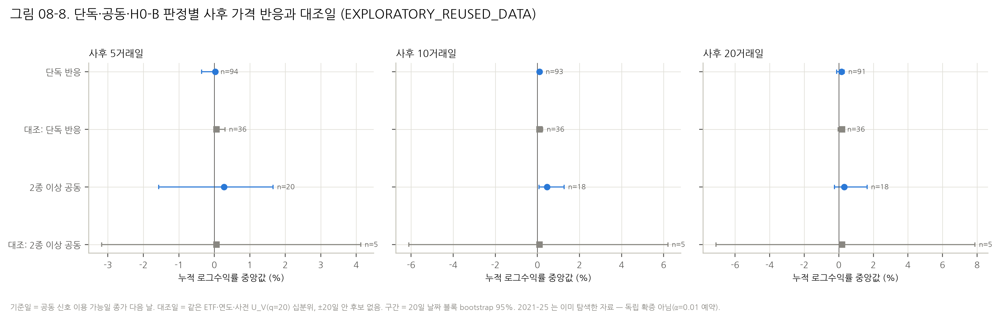

In [20]:
# 가격 반응 요약 · 미래 확증 검정의 필요 표본 · 그림 08-8
PRICE = A.price_response(OBS, EP, QS, seed=int(CFG["seed"]))  # 탐색 분석
save_csv(PRICE["summary"], "price_response_summary.csv")  # 요약만 Git (일별 수익률 미포함)
with gzip.GzipFile(WORK / "price_events.csv.gz", "wb", mtime=0) as fh:  # 사건별 수익률은 Git 제외
    fh.write(PRICE["events"].to_csv(index=False, float_format="%.10g").encode())  # 저장
display(PRICE["summary"][["group", "h", "n_events", "n_date_blocks", "median_ret", "ci95_low", "ci95_high", "median_rel_vs_other5", "share_up", "reversal_share", "label"]].round(3))  # 요약
REQ = A.confirmatory_power_requirement(PRICE["summary"], PRICE["events"])  # 미래 확증 설계
save_csv(REQ, "price_future_confirmatory_requirement.csv")  # 근거
display(REQ.round(3))  # 표
P8 = F.fig_price(PRICE["summary"], FIG, "08-8")  # 가격 그림
display(Image(filename=str(P8[0]), width=950))  # 렌더 확인

**해석 (17, `EXPLORATORY_REUSED_DATA`).**
- **단독 반응 사건 (94개, 날짜 블록 41개).** 사후 5일 누적수익률 중앙값은 0.024% [−0.356, 0.065] 로 0 근처다.
- **2종 이상 공동 반응 사건 (20개, 블록 7개).**
  - 사후 10일 중앙값은 0.461% [0.083, 1.272] 다.
  - 같은 조건의 대조일은 5개뿐이라 구간이 [−6.1, 6.2] 로 넓어 비교할 수 없다.
- **H0-B 유의 구간.** 없으므로 그 그룹은 비어 있다.
- **G7 Q14 (사후 가격반응: 개별 국면 대 공동 국면).** 표본이 작고 겹쳐 있어 차이를 말할 수 없다.
- **미래 확증 설계.**
  - 관측 차이를 효과크기로 두고, α = 0.01·검정력 0.8 을 맞추려면 그룹당 497 (5일) · 765 (10일) 사건이 필요하다.
  - 현재 자료로는 확증할 수 없다. 예약한 α = 0.01 은 쓰지 않았다.
  - W2 의 −0.84%p 결과를 검증된 가설로 쓰지 않는다.

## 18. 2024년 8월·2025년 4월 사례

통계 설계와 임계값을 모두 확정한 **뒤에** 해석한다. 사례 창은 승인서 §18 G6 이 지정했다. 사례 날짜를 실시간 조기 탐지에 성공한 날로 읽지 않는다.

In [21]:
# 두 사례 창과 겹치는 공동 구간 (모든 집합) — 날짜·참여·판정·방향
for name, (a, b) in CASES.items():  # 두 사례
    m = (pd.to_datetime(EP.episode_end_at) >= pd.Timestamp(a)) & (pd.to_datetime(EP.episode_start_at) <= pd.Timestamp(b))  # 창과 겹침
    sub = EP[m].sort_values("cumulative_excess", ascending=False)  # 겹치는 구간
    save_csv(sub, f"case_episodes_{name[:7]}.csv")  # 근거
    print(name, "| 겹치는 공동 구간", len(sub), "개 | 유의일 판정 분포", sub.day_level_status.value_counts().to_dict())  # 요약
    display(sub.head(10)[["subset", "episode_start_at", "episode_end_at", "joint_confirmed_at", "max_J", "cumulative_excess", "day_level_status", "direction"]])  # 상위

2024-08 (2024-07-25~09-30) | 겹치는 공동 구간 0 개 | 유의일 판정 분포 {}


,subset,episode_start_at,episode_end_at,joint_confirmed_at,max_J,cumulative_excess,day_level_status,direction


2025-04 (2025-03-25~05-30) | 겹치는 공동 구간 2 개 | 유의일 판정 분포 {'NULL_MODEL_INVALID': 2}


,subset,episode_start_at,episode_end_at,joint_confirmed_at,max_J,cumulative_excess,day_level_status,direction
8,153130+261220,2025-04-04,2025-04-08,2025-04-07,5.688659,3.183647,NULL_MODEL_INVALID,COMMON_EXPANSION
9,153130+261220,2025-04-10,2025-04-11,2025-04-10,5.372141,1.369509,NULL_MODEL_INVALID,MIXED


**해석 (18).** 통계 설계와 임계값을 확정한 뒤 사례를 해석했다.

- **2024-08.**
  - 어느 집합에도 탐색 공동 구간(J ≥ c0)이 없다.
  - 창 안에서 S1 J_all 최대값은 4.446 (2024-08-30) 이다.
  - 069500 의 개별 Q 는 그 창에서 5.93 까지 올랐지만, 229200 이 4.45 에 그쳐 "둘 다 1% 꼬리" 조건을 채우지 못했다.
  - 다중 기간 확대 후보는 6종 모두 07-25~08-07 에 켜졌다 (W2 의 관찰과 일치). 그러나 잔차 CUSUM 의 공동 극단으로는 이어지지 않았다.
- **2025-04.**
  - 공동 구간은 153130+261220 두 개다: 04-04~04-08 (공동 확대), 04-10~04-11 (혼합).
  - 두 구간 모두 귀무 부적합 집합에 속한다.
  - S1 J_all 은 창 안 최대 3.027 로 낮았다.
- **결론.** 사례 날짜는 실시간 조기 탐지 성공으로 읽지 않는다.

## 19. 결과·비지지 가설·연구 한계

### 가설·조합별 판정

| 대상 | 판정 | 근거 |
|---|---|---|
| H1 개별 잔차 분산 불안정성 | 기술. W3 임계 경보 45 ETF-정책-창-일 (153130·261220·133690 에서만) | 04장 |
| H2 (H0-A) 시간 정렬 | 비유의. S1 0.627·0.602, 부분집합 최소 0.024 > 3.5e-4 | 11–12장 |
| **H3 (H0-B) S1** | **`NULL_MODEL_INVALID`** (069500 N3). 원시 p 0.853 | 07장 |
| H4 S2·S3 | `NOT_ESTIMABLE` (E₁ 비어 있음 — 참여 부재의 증거 아님) | 08장 |
| H4 S4·S5 | `NULL_MODEL_INVALID` · 사슬 중단 (원시 p 0.855·0.953) | 09장 |
| 부분집합 57 | 56 `NULL_MODEL_INVALID` · 1 (229200+133690) `NOT_SIGNIFICANT` p=0.270 | 10장 |
| 공동 구간 | 유의 구간 0개. 탐색 구간 10개 (모두 쌍) | 15장 |
| H5 의존구조 변화 | 탐색 기술만 (평균 상관 변화 +0.105) | 16장 |
| H6 가격 | `EXPLORATORY_REUSED_DATA`. 확증 필요 표본 497–765 /그룹 | 17장 |
| 검출력 | V1 경로 기각 0.043 ≈ 크기 · 유의일 검출 0/300 → 사실상 없음 | 13장 |
| 단기 창 3·7·14 | `NOT_ELIGIBLE` (크기 통과, 검출 실패) | 05장 |

### 최종 판정

- **`LOW_POWER_INCONCLUSIVE` (주).**
  - 설계한 공동 분산 변화조차 검정 크기 수준으로만 잡혔다.
  - 그러므로 유의 구간이 없다는 사실은 "추가 공동 불안정성이 없다" 는 뜻이 아니다.
- **`NULL_MODEL_INVALID` (주 경로 전 단계, 부분집합 56/57).**
  - DCC-t 귀무는 069500 의 변동성 군집, 261220 의 꼬리, 153130 의 이산성, 148070 의 지속성을 재현하지 못했다.
- **`NO_SIGNIFICANT_COMMON_INTERVAL`.**
  - 유효한 유일 조합 229200+133690 이 비유의다.
  - 원시 p 를 보아도 최소 0.040 으로 기준에서 멀다.
- **쓸 수 없는 판정.** `COMMON_SYNCHRONIZATION_EXPLAINED_BY_NULL` 은 검출력이 없어서 쓸 수 없다.
- **쓰지 않은 판정.** `INSUFFICIENT_MONTE_CARLO`·`BLOCKED_BY_COMPUTE` 는 해당 사항이 없다 (해상도 충족, 13.1시간).

### 비지지 가설·한계

- **비지지 가설.** "KOSPI·KOSDAQ 의 CUSUM 이 정상 동조성을 넘어 함께 반응한다" 는 가설은 지지되지 않았다. 다만 이 검정은 그런 반응을 잡을 힘이 없었다.
- **표준화 효과.** 잔차 CUSUM 은 SVR 예측분산이 변동성을 흡수한 뒤의 통계량이다. 그래서 가격 변동성의 공동 급등을 직접 재는 도구가 아니다.
  - 다음 연구는 표준화 전 수익률 또는 예측 오차(QLIKE) 수준의 공동 통계량으로 검출력을 먼저 확인해야 한다.
- **귀무모형.** 결합 자유도가 하나뿐인 DCC-t 는 이 6종의 꼬리와 이산성을 재현하지 못한다. 대안 결합(t-copula 등)은 이번 연구에서 사후로 시도하지 않았다.
- **자료.** 2021–2025 는 W1·W2 에서 이미 본 자료다. 독립 외부 검증이 아니다.

## 20. 재현성 및 최종 감사

- 본문 수치는 아래 CLAIMS 가 이 실행의 결과와 대조한다.
- 결과 파일과 그림의 SHA256 은 `figure_index_08.csv` 와 `results_index_08.csv` 에 기록한다.
- MC 산출물은 첫 셀에서 `inference_meta.json` 의 해시와 대조했다.

In [22]:
# 본문 수치 대조 (CLAIMS) — 해석 문단에 적은 값과 이번 실행 결과가 같아야 한다
CLAIMS = json.loads((ROOT / "research/joint_cusum_w3/notebook_claims.json").read_text(encoding="utf-8"))  # 해석 문단의 수치 목록
ENV = {"STAGE": STAGE, "SUB": SUB, "SIZE": SIZE, "POWER": POWER, "EP": EP, "VAL": VAL, "COND": COND, "ELIG": ELIG, "PRICE": PRICE, "LAGSUM": LAGSUM, "INDIV": INDIV, "CASE_T": CASE_T, "W1CHK": W1CHK, "SEQ": SEQ, "V1D": V1D, "ROB": ROB, "H0AD": H0AD, "REPRO": REPRO, "VDET": VDET, "CORR": CORR, "REQ": REQ, "np": np, "pd": pd}  # 평가 이름공간
bad = []  # 불일치 목록
for c in CLAIMS:  # 하나씩
    got = eval(c["expr"], {}, ENV)  # 결과에서 계산 (식은 저장소에 커밋된 JSON)
    if (isinstance(c["want"], float) and not np.isclose(float(got), c["want"], atol=c.get("atol", 0))) or (not isinstance(c["want"], float) and got != c["want"]):  # 비교
        bad.append((c["id"], got, c["want"]))  # 불일치 기록
print("CLAIMS", len(CLAIMS), "개 중 불일치", len(bad))  # 요약
assert not bad, bad  # 하나라도 다르면 중단

CLAIMS 80 개 중 불일치 0


In [23]:
# 결과·그림 색인과 해시 (결정적 형식) — 감사 근거
fig_idx = pd.DataFrame([{"file": p.name, "sha256": sha(p)} for p in sorted(FIG.glob("fig08_*"))])  # 그림 색인
res_idx = pd.DataFrame([{"file": p.name, "sha256": sha(p)} for p in sorted(RES.glob("*.csv")) if p.name not in ("figure_index_08.csv", "results_index_08.csv")])  # 결과 색인
fig_idx.to_csv(RES / "figure_index_08.csv", index=False)  # 저장
res_idx.to_csv(RES / "results_index_08.csv", index=False)  # 저장
print("그림", len(fig_idx), "개 · 결과표", len(res_idx), "개 · 일별 Git 제외 파일:", sorted(p.name for p in WORK.iterdir()))  # 요약

그림 20 개 · 결과표 37 개 · 일별 Git 제외 파일: ['joint_daily.csv.gz', 'price_events.csv.gz']
